In [ ]:
import pandas as pd

In [ ]:
url_adult = "https://ourworldindata.org/grapher/literacy-rate-adults.csv"

df_adult = pd.read_csv(url_adult)

df_adult.head()

,Entity,Code,Year,Literacy rate among adults
0,Afghanistan,AFG,1979,18.160000
1,Afghanistan,AFG,2011,31.450000
2,Afghanistan,AFG,2015,33.750000
3,Afghanistan,AFG,2020,36.014965
4,Afghanistan,AFG,2021,37.270000


In [ ]:
import requests
import pandas as pd
from io import StringIO

url_adult = "https://ourworldindata.org/grapher/literacy-rate-adults.csv"

headers = {
    "User-Agent": "Mozilla/5.0"
}

response = requests.get(url_adult, headers=headers)

print(response.status_code)

200


In [ ]:
data = response.text

df_adult = pd.read_csv(StringIO(data))

df_adult.head()

,Entity,Code,Year,Literacy rate among adults
0,Afghanistan,AFG,1979,18.160000
1,Afghanistan,AFG,2011,31.450000
2,Afghanistan,AFG,2015,33.750000
3,Afghanistan,AFG,2020,36.014965
4,Afghanistan,AFG,2021,37.270000


In [ ]:
print("Shape:", df_adult.shape)

print("\nColumns:")
print(df_adult.columns)

print("\nData Info:")
df_adult.info()

Shape: (1833, 4)

Columns:
Index(['Entity', 'Code', 'Year', 'Literacy rate among adults'], dtype='object')

Data Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1833 entries, 0 to 1832
Data columns (total 4 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Entity                      1833 non-null   object 
 1   Code                        1560 non-null   object 
 2   Year                        1833 non-null   int64  
 3   Literacy rate among adults  1833 non-null   float64
dtypes: float64(1), int64(1), object(2)
memory usage: 57.4+ KB


In [ ]:
urls = {
    "youth": "https://ourworldindata.org/grapher/literacy-rate-of-young-men-and-women.csv",
    "illiteracy": "https://ourworldindata.org/grapher/literate-and-illiterate-world-population.csv",
    "gdp": "https://ourworldindata.org/grapher/gdp-per-capita-worldbank.csv",
    "schooling": "https://ourworldindata.org/grapher/literacy-rates-vs-average-years-of-schooling.csv"
}

responses = {}

for name, url in urls.items():
    responses[name] = requests.get(url, headers=headers)
    print(name, responses[name].status_code)

youth 200
illiteracy 200
gdp 200
schooling 200


In [ ]:
df_youth = pd.read_csv(StringIO(responses["youth"].text))
df_illiteracy = pd.read_csv(StringIO(responses["illiteracy"].text))
df_gdp = pd.read_csv(StringIO(responses["gdp"].text))
df_schooling = pd.read_csv(StringIO(responses["schooling"].text))

print("Youth:", df_youth.shape)
print("Illiteracy:", df_illiteracy.shape)
print("GDP:", df_gdp.shape)
print("Schooling:", df_schooling.shape)

Youth: (2077, 6)
Illiteracy: (2167, 5)
GDP: (7445, 5)
Schooling: (5403, 7)


In [ ]:
print("===== ADULT LITERACY =====")
print(df_adult.columns.tolist())

print("\n===== YOUTH LITERACY =====")
print(df_youth.columns.tolist())

print("\n===== ILLITERACY =====")
print(df_illiteracy.columns.tolist())

print("\n===== GDP =====")
print(df_gdp.columns.tolist())

print("\n===== SCHOOLING =====")
print(df_schooling.columns.tolist())

===== ADULT LITERACY =====
['Entity', 'Code', 'Year', 'Literacy rate among adults']

===== YOUTH LITERACY =====
['Entity', 'Code', 'Year', 'Literacy rate among young men', 'Literacy rate among young women', 'World region according to OWID']

===== ILLITERACY =====
['Entity', 'Code', 'Year', 'Illiterate', 'Literate']

===== GDP =====
['Entity', 'Code', 'Year', 'GDP per capita', 'World region according to OWID']

===== SCHOOLING =====
['Entity', 'Code', 'Year', 'Literacy rate', 'Average years of education for 15-64 years olds', 'Population', 'World region according to OWID']


In [ ]:
print("Adult:", df_adult["Year"].min(), "to", df_adult["Year"].max())
print("Youth:", df_youth["Year"].min(), "to", df_youth["Year"].max())
print("Illiteracy:", df_illiteracy["Year"].min(), "to", df_illiteracy["Year"].max())
print("GDP:", df_gdp["Year"].min(), "to", df_gdp["Year"].max())
print("Schooling:", df_schooling["Year"].min(), "to", df_schooling["Year"].max())

Adult: 1970 to 2024
Youth: 1970 to 2024
Illiteracy: 1475 to 2024
GDP: 1990 to 2025
Schooling: 1475 to 2023


In [ ]:
df_adult = df_adult[
    (df_adult["Year"] >= 1990) &
    (df_adult["Year"] <= 2023)
]

df_youth = df_youth[
    (df_youth["Year"] >= 1990) &
    (df_youth["Year"] <= 2023)
]

df_illiteracy = df_illiteracy[
    (df_illiteracy["Year"] >= 1990) &
    (df_illiteracy["Year"] <= 2023)
]

df_gdp = df_gdp[
    (df_gdp["Year"] >= 1990) &
    (df_gdp["Year"] <= 2023)
]

df_schooling = df_schooling[
    (df_schooling["Year"] >= 1990) &
    (df_schooling["Year"] <= 2023)
]

print("Filtering completed successfully!")

Filtering completed successfully!


In [ ]:
print("ADULT LITERACY")
print(df_adult.isnull().sum())

print("\nYOUTH LITERACY")
print(df_youth.isnull().sum())

print("\nILLITERACY")
print(df_illiteracy.isnull().sum())

print("\nGDP")
print(df_gdp.isnull().sum())

print("\nSCHOOLING")
print(df_schooling.isnull().sum())

ADULT LITERACY
Entity                          0
Code                          204
Year                            0
Literacy rate among adults      0
dtype: int64

YOUTH LITERACY
Entity                               0
Code                               208
Year                                 0
Literacy rate among young men       82
Literacy rate among young women      6
World region according to OWID     530
dtype: int64

ILLITERACY
Entity          0
Code          204
Year            0
Illiterate      0
Literate        0
dtype: int64

GDP
Entity                              0
Code                                0
Year                                0
GDP per capita                      0
World region according to OWID    442
dtype: int64

SCHOOLING
Entity                                                0
Code                                                204
Year                                                  0
Literacy rate                                       725
Average years o

In [ ]:
print("Adult duplicates:", df_adult.duplicated().sum())
print("Youth duplicates:", df_youth.duplicated().sum())
print("Illiteracy duplicates:", df_illiteracy.duplicated().sum())
print("GDP duplicates:", df_gdp.duplicated().sum())
print("Schooling duplicates:", df_schooling.duplicated().sum())

Adult duplicates: 0
Youth duplicates: 0
Illiteracy duplicates: 0
GDP duplicates: 0
Schooling duplicates: 0


In [ ]:
print("Adult countries:", df_adult["Entity"].nunique())
print("Youth countries:", df_youth["Entity"].nunique())
print("Illiteracy countries:", df_illiteracy["Entity"].nunique())
print("GDP countries:", df_gdp["Entity"].nunique())
print("Schooling countries:", df_schooling["Entity"].nunique())

Adult countries: 184
Youth countries: 188
Illiteracy countries: 184
GDP countries: 212
Schooling countries: 219


In [ ]:
print(df_adult["Entity"].unique()[:50])

['Afghanistan' 'Albania' 'Algeria' 'Angola' 'Antigua and Barbuda'
 'Argentina' 'Armenia' 'Aruba' 'Azerbaijan' 'Bahrain' 'Bangladesh'
 'Belarus' 'Belize' 'Benin' 'Bhutan' 'Bolivia' 'Bosnia and Herzegovina'
 'Botswana' 'Brazil' 'Brunei' 'Bulgaria' 'Burkina Faso' 'Burundi'
 'Cambodia' 'Cameroon' 'Cape Verde' 'Cayman Islands'
 'Central African Republic' 'Central and Southern Asia (SDG)' 'Chad'
 'Chile' 'China' 'Colombia' 'Comoros' 'Congo' 'Costa Rica' "Cote d'Ivoire"
 'Croatia' 'Cuba' 'Cyprus' 'Democratic Republic of Congo'
 'Dominican Republic' 'East Asia and Pacific (WB)' 'East Timor'
 'Eastern and South-Eastern Asia (SDG)' 'Ecuador' 'Egypt' 'El Salvador'
 'Equatorial Guinea' 'Eritrea']


In [ ]:
df_adult[df_adult["Code"].isna()][["Entity", "Year"]].head(20)

,Entity,Year
201,Central and Southern Asia (SDG),1990
202,Central and Southern Asia (SDG),1991
203,Central and Southern Asia (SDG),1992
204,Central and Southern Asia (SDG),1993
205,Central and Southern Asia (SDG),1994
206,Central and Southern Asia (SDG),1995
207,Central and Southern Asia (SDG),1996
208,Central and Southern Asia (SDG),1997
209,Central and Southern Asia (SDG),1998
210,Central and Southern Asia (SDG),1999


In [ ]:
df_adult[df_adult["Code"].isna()]["Entity"].unique()

array(['Central and Southern Asia (SDG)',
       'Eastern and South-Eastern Asia (SDG)',
       'Europe and Northern America (SDG)',
       'Latin America and the Caribbean (SDG)',
       'Northern Africa and Western Asia (SDG)',
       'Oceania (excluding Australia and New Zealand) (SDG)',
       'Sub-Saharan Africa (SDG)'], dtype=object)

In [ ]:
df_adult = df_adult[df_adult["Code"].notna()].copy()
df_youth = df_youth[df_youth["Code"].notna()].copy()
df_illiteracy = df_illiteracy[df_illiteracy["Code"].notna()].copy()
df_gdp = df_gdp[df_gdp["Code"].notna()].copy()
df_schooling = df_schooling[df_schooling["Code"].notna()].copy()

print("Region/Aggregate rows removed successfully!")

Region/Aggregate rows removed successfully!


In [ ]:
import pandas as pd
import numpy as np
import requests
from io import StringIO

headers = {
    "User-Agent": "Mozilla/5.0"
}

urls = {
    "adult": "https://ourworldindata.org/grapher/literacy-rate-adults.csv",
    "youth": "https://ourworldindata.org/grapher/literacy-rate-of-young-men-and-women.csv",
    "illiteracy": "https://ourworldindata.org/grapher/literate-and-illiterate-world-population.csv",
    "gdp": "https://ourworldindata.org/grapher/gdp-per-capita-worldbank.csv",
    "schooling": "https://ourworldindata.org/grapher/literacy-rates-vs-average-years-of-schooling.csv"
}

responses = {}

for name, url in urls.items():
    responses[name] = requests.get(url, headers=headers)
    print(name, responses[name].status_code)

adult 200
youth 200
illiteracy 200
gdp 200
schooling 200


In [ ]:
df_adult = pd.read_csv(StringIO(responses["adult"].text))
df_youth = pd.read_csv(StringIO(responses["youth"].text))
df_illiteracy = pd.read_csv(StringIO(responses["illiteracy"].text))
df_gdp = pd.read_csv(StringIO(responses["gdp"].text))
df_schooling = pd.read_csv(StringIO(responses["schooling"].text))

print("Adult:", df_adult.shape)
print("Youth:", df_youth.shape)
print("Illiteracy:", df_illiteracy.shape)
print("GDP:", df_gdp.shape)
print("Schooling:", df_schooling.shape)

Adult: (1833, 4)
Youth: (2077, 6)
Illiteracy: (2167, 5)
GDP: (7445, 5)
Schooling: (5403, 7)


In [ ]:
df_adult = df_adult[
    (df_adult["Year"] >= 1990) &
    (df_adult["Year"] <= 2023)
]

df_youth = df_youth[
    (df_youth["Year"] >= 1990) &
    (df_youth["Year"] <= 2023)
]

df_illiteracy = df_illiteracy[
    (df_illiteracy["Year"] >= 1990) &
    (df_illiteracy["Year"] <= 2023)
]

df_gdp = df_gdp[
    (df_gdp["Year"] >= 1990) &
    (df_gdp["Year"] <= 2023)
]

df_schooling = df_schooling[
    (df_schooling["Year"] >= 1990) &
    (df_schooling["Year"] <= 2023)
]

print("1990–2023 filtering completed!")

1990–2023 filtering completed!


In [ ]:
print("ADULT LITERACY")
print(df_adult.isnull().sum())

print("\nYOUTH LITERACY")
print(df_youth.isnull().sum())

print("\nILLITERACY")
print(df_illiteracy.isnull().sum())

print("\nGDP")
print(df_gdp.isnull().sum())

print("\nSCHOOLING")
print(df_schooling.isnull().sum())

ADULT LITERACY
Entity                          0
Code                          204
Year                            0
Literacy rate among adults      0
dtype: int64

YOUTH LITERACY
Entity                               0
Code                               208
Year                                 0
Literacy rate among young men       82
Literacy rate among young women      6
World region according to OWID     530
dtype: int64

ILLITERACY
Entity          0
Code          204
Year            0
Illiterate      0
Literate        0
dtype: int64

GDP
Entity                              0
Code                                0
Year                                0
GDP per capita                      0
World region according to OWID    442
dtype: int64

SCHOOLING
Entity                                                0
Code                                                204
Year                                                  0
Literacy rate                                       725
Average years o

In [ ]:
print("Adult duplicates:", df_adult.duplicated().sum())
print("Youth duplicates:", df_youth.duplicated().sum())
print("Illiteracy duplicates:", df_illiteracy.duplicated().sum())
print("GDP duplicates:", df_gdp.duplicated().sum())
print("Schooling duplicates:", df_schooling.duplicated().sum())

Adult duplicates: 0
Youth duplicates: 0
Illiteracy duplicates: 0
GDP duplicates: 0
Schooling duplicates: 0


In [ ]:
print(df_adult[df_adult["Code"].isna()]["Entity"].unique())

['Central and Southern Asia (SDG)' 'Eastern and South-Eastern Asia (SDG)'
 'Europe and Northern America (SDG)'
 'Latin America and the Caribbean (SDG)'
 'Northern Africa and Western Asia (SDG)'
 'Oceania (excluding Australia and New Zealand) (SDG)'
 'Sub-Saharan Africa (SDG)']


In [ ]:
df_adult = df_adult[
    ~df_adult["Entity"].str.contains("(SDG)", regex=False, na=False)
]

In [ ]:
print(df_adult["Code"].isna().sum())

0


In [ ]:
print("Adult duplicates:", df_adult.duplicated().sum())

Adult duplicates: 0


In [ ]:
print("Shape:", df_adult.shape)
print("Columns:", df_adult.columns.tolist())

Shape: (1310, 4)
Columns: ['Entity', 'Code', 'Year', 'Literacy rate among adults']


In [ ]:
print(df_adult["Literacy rate among adults"].min())
print(df_adult["Literacy rate among adults"].max())

10.89
100.0


In [ ]:
df_adult = df_adult.rename(
    columns={"Literacy rate among adults": "Adult_Literacy_Rate"}
)

In [ ]:
print(df_adult.columns.tolist())

['Entity', 'Code', 'Year', 'Adult_Literacy_Rate']


In [ ]:
print(df_adult.dtypes)

Entity                  object
Code                    object
Year                     int64
Adult_Literacy_Rate    float64
dtype: object


In [ ]:
print(df_adult.dtypes)

Entity                  object
Code                    object
Year                     int64
Adult_Literacy_Rate    float64
dtype: object


In [ ]:
import requests
import pandas as pd
from io import StringIO

url_adult = "https://ourworldindata.org/grapher/literacy-rate-adults.csv"
headers = {"User-Agent": "Mozilla/5.0"}

response = requests.get(url_adult, headers=headers)

print(response.status_code)

200


In [ ]:
data = response.text
df_adult = pd.read_csv(StringIO(data))

print(df_adult.shape)

(1833, 4)


In [ ]:
df_adult = df_adult[
    (df_adult["Year"] >= 1990) &
    (df_adult["Year"] <= 2023)
]

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
df_adult = df_adult[
    ~df_adult["Entity"].str.contains("(SDG)", regex=False, na=False)
]

In [ ]:
print(df_adult["Code"].isna().sum())
print(df_adult.duplicated().sum())

0
0


In [ ]:
df_adult = df_adult.rename(
    columns={"Literacy rate among adults": "Adult_Literacy_Rate"}
)

In [ ]:
print(df_adult.dtypes)

Entity                  object
Code                    object
Year                     int64
Adult_Literacy_Rate    float64
dtype: object


In [ ]:
print(df_adult.head())

        Entity Code  Year  Adult_Literacy_Rate
1  Afghanistan  AFG  2011            31.450000
2  Afghanistan  AFG  2015            33.750000
3  Afghanistan  AFG  2020            36.014965
4  Afghanistan  AFG  2021            37.270000
5      Albania  ALB  2001            98.710000


In [ ]:
print("Final Adult Dataset Shape:", df_adult.shape)

Final Adult Dataset Shape: (1310, 4)


In [ ]:
url_youth = "https://ourworldindata.org/grapher/literacy-rate-of-young-men-and-women.csv"

response_youth = requests.get(url_youth, headers=headers)

print(response_youth.status_code)

200


In [ ]:
data_youth = response_youth.text
df_youth = pd.read_csv(StringIO(data_youth))

print(df_youth.shape)

(2077, 6)


In [ ]:
df_youth = df_youth[
    (df_youth["Year"] >= 1990) &
    (df_youth["Year"] <= 2023)
]

In [ ]:
print(df_youth.shape)

(1757, 6)


In [ ]:
print(df_youth.isna().sum())

Entity                               0
Code                               208
Year                                 0
Literacy rate among young men       82
Literacy rate among young women      6
World region according to OWID     530
dtype: int64


In [ ]:
print(df_youth[df_youth["Code"].isna()]["Entity"].unique())

['Central and Southern Asia (SDG)' 'Eastern and South-Eastern Asia (SDG)'
 'Europe and Northern America (SDG)'
 'Latin America and the Caribbean (SDG)'
 'Northern Africa and Western Asia (SDG)'
 'Oceania (excluding Australia and New Zealand) (SDG)'
 'Sub-Saharan Africa (SDG)']


In [ ]:
df_youth = df_youth[
    ~df_youth["Entity"].str.contains("(SDG)", regex=False, na=False)
]

In [ ]:
print(df_youth["Code"].isna().sum())

0


In [ ]:
print(df_youth.isna().sum())

Entity                               0
Code                                 0
Year                                 0
Literacy rate among young men       82
Literacy rate among young women      5
World region according to OWID     322
dtype: int64


In [ ]:
print(df_youth[df_youth["Literacy rate among young men"].isna()][["Entity", "Code", "Year"]].head(20))

                           Entity Code  Year
7                         Albania  ALB  2005
18                        Algeria  DZA  2019
66                     Bangladesh  BGD  2006
84                        Belarus  BLR  2005
90                         Belize  BLZ  2006
91                         Belize  BLZ  2011
99                          Benin  BEN  2011
106                        Bhutan  BTN  2010
137        Bosnia and Herzegovina  BIH  2006
186                  Burkina Faso  BFA  2023
190                       Burundi  BDI  2005
198                      Cambodia  KHM  2000
214                      Cameroon  CMR  2006
229      Central African Republic  CAF  2006
230      Central African Republic  CAF  2010
285                          Chad  TCD  2010
307                      Colombia  COL  2000
341                    Costa Rica  CRI  2018
345                 Cote d'Ivoire  CIV  2006
361  Democratic Republic of Congo  COD  2010


In [ ]:
missing_men = df_youth["Literacy rate among young men"].isna().sum()
total_rows = len(df_youth)

print("Missing:", missing_men)
print("Total rows:", total_rows)
print("Missing percentage:", round((missing_men / total_rows) * 100, 2), "%")

Missing: 82
Total rows: 1549
Missing percentage: 5.29 %


In [ ]:
df_youth = df_youth.dropna(
    subset=["Literacy rate among young men"]
)

In [ ]:
print(df_youth["Literacy rate among young men"].isna().sum())
print(df_youth.shape)

0
(1467, 6)


In [ ]:
print(df_youth[df_youth["Literacy rate among young women"].isna()][
    ["Entity", "Code", "Year"]
])

             Entity Code  Year
350   Cote d'Ivoire  CIV  2022
1230        Nigeria  NGA  2019
1540        Senegal  SEN  2022
2066         Zambia  ZMB  2019
2070         Zambia  ZMB  2023


In [ ]:
df_youth = df_youth.dropna(
    subset=["Literacy rate among young women"]
)

In [ ]:
print(df_youth["Literacy rate among young women"].isna().sum())
print(df_youth.shape)

0
(1462, 6)


In [ ]:
df_youth = df_youth.drop(
    columns=["World region according to OWID"]
)

In [ ]:
print(df_youth.columns.tolist())

['Entity', 'Code', 'Year', 'Literacy rate among young men', 'Literacy rate among young women']


In [ ]:
df_youth = df_youth.rename(columns={
    "Literacy rate among young men": "Youth_Male_Literacy_Rate",
    "Literacy rate among young women": "Youth_Female_Literacy_Rate"
})

In [ ]:
print(df_youth.dtypes)

Entity                         object
Code                           object
Year                            int64
Youth_Male_Literacy_Rate      float64
Youth_Female_Literacy_Rate    float64
dtype: object


In [ ]:
print("Male min:", df_youth["Youth_Male_Literacy_Rate"].min())
print("Male max:", df_youth["Youth_Male_Literacy_Rate"].max())

print("Female min:", df_youth["Youth_Female_Literacy_Rate"].min())
print("Female max:", df_youth["Youth_Female_Literacy_Rate"].max())

Male min: 25.48
Male max: 100.0
Female min: 8.95
Female max: 100.0


In [ ]:
print("Youth duplicates:", df_youth.duplicated().sum())

Youth duplicates: 0


In [ ]:
print("Male literacy min:", df_youth["Youth_Male_Literacy_Rate"].min())
print("Male literacy max:", df_youth["Youth_Male_Literacy_Rate"].max())

print("Female literacy min:", df_youth["Youth_Female_Literacy_Rate"].min())
print("Female literacy max:", df_youth["Youth_Female_Literacy_Rate"].max())

Male literacy min: 25.48
Male literacy max: 100.0
Female literacy min: 8.95
Female literacy max: 100.0


In [ ]:
print(df_youth.columns)
print(df_youth.head())

Index(['Entity', 'Code', 'Year', 'Youth_Male_Literacy_Rate',
       'Youth_Female_Literacy_Rate'],
      dtype='object')
        Entity Code  Year  Youth_Male_Literacy_Rate  \
1  Afghanistan  AFG  2011                 61.880000   
2  Afghanistan  AFG  2015                 57.740000   
3  Afghanistan  AFG  2020                 68.800964   
4  Afghanistan  AFG  2021                 71.240000   
5  Afghanistan  AFG  2022                 83.400000   

   Youth_Female_Literacy_Rate  
1                   32.110000  
2                   25.480000  
3                   40.055595  
4                   41.590000  
5                   44.170000  


In [ ]:
url_illiteracy = "https://ourworldindata.org/grapher/literate-and-illiterate-world-population.csv"

response_illiteracy = requests.get(url_illiteracy, headers=headers)

print(response_illiteracy.status_code)

data_illiteracy = response_illiteracy.text

df_illiteracy = pd.read_csv(StringIO(data_illiteracy))

print(df_illiteracy.shape)
print(df_illiteracy.head())

200
(2167, 5)
        Entity Code  Year  Illiterate   Literate
0  Afghanistan  AFG  1950   97.000000   3.000000
1  Afghanistan  AFG  1979   81.840000  18.160000
2  Afghanistan  AFG  2011   68.550000  31.450000
3  Afghanistan  AFG  2015   66.250000  33.750000
4  Afghanistan  AFG  2020   63.985035  36.014965


In [ ]:
df_illiteracy = df_illiteracy[
    (df_illiteracy["Year"] >= 1990) &
    (df_illiteracy["Year"] <= 2023)
]

print(df_illiteracy.shape)
print(df_illiteracy["Year"].min(), df_illiteracy["Year"].max())

(1513, 5)
1990 2023


In [ ]:
print(df_illiteracy.isna().sum())

Entity          0
Code          204
Year            0
Illiterate      0
Literate        0
dtype: int64


In [ ]:
print(df_illiteracy[df_illiteracy["Code"].isna()]["Entity"].unique())

['Central and Southern Asia (SDG)' 'Eastern and South-Eastern Asia (SDG)'
 'Europe and Northern America (SDG)'
 'Latin America and the Caribbean (SDG)'
 'Northern Africa and Western Asia (SDG)'
 'Oceania (excluding Australia and New Zealand) (SDG)'
 'Sub-Saharan Africa (SDG)']


In [ ]:
df_illiteracy = df_illiteracy[
    ~df_illiteracy["Entity"].str.contains("(SDG)", regex=False, na=False)
]

print(df_illiteracy.shape)
print(df_illiteracy.isna().sum())

(1309, 5)
Entity        0
Code          0
Year          0
Illiterate    0
Literate      0
dtype: int64


In [ ]:
print("Illiteracy duplicates:", df_illiteracy.duplicated().sum())

Illiteracy duplicates: 0


In [ ]:
print("Illiterate min:", df_illiteracy["Illiterate"].min())
print("Illiterate max:", df_illiteracy["Illiterate"].max())

print("Literate min:", df_illiteracy["Literate"].min())
print("Literate max:", df_illiteracy["Literate"].max())

Illiterate min: 0.0
Illiterate max: 89.11
Literate min: 10.89
Literate max: 100.0


In [ ]:
df_illiteracy = df_illiteracy.rename(columns={
    "Illiterate": "Illiterate_Percentage",
    "Literate": "Literate_Percentage"
})

print(df_illiteracy.columns)

Index(['Entity', 'Code', 'Year', 'Illiterate_Percentage',
       'Literate_Percentage'],
      dtype='object')


In [ ]:
print(df_illiteracy.dtypes)
print(df_illiteracy.head())

Entity                    object
Code                      object
Year                       int64
Illiterate_Percentage    float64
Literate_Percentage      float64
dtype: object
        Entity Code  Year  Illiterate_Percentage  Literate_Percentage
2  Afghanistan  AFG  2011              68.550000            31.450000
3  Afghanistan  AFG  2015              66.250000            33.750000
4  Afghanistan  AFG  2020              63.985035            36.014965
5  Afghanistan  AFG  2021              62.730000            37.270000
7      Albania  ALB  2001               1.290001            98.710000


In [ ]:
url_gdp = "https://ourworldindata.org/grapher/gdp-per-capita-worldbank.csv"

response_gdp = requests.get(url_gdp, headers=headers)

print(response_gdp.status_code)

data_gdp = response_gdp.text

df_gdp = pd.read_csv(StringIO(data_gdp))

print(df_gdp.shape)
print(df_gdp.head())

200
(7445, 5)
        Entity Code  Year  GDP per capita World region according to OWID
0  Afghanistan  AFG  2000       1617.8264                           Asia
1  Afghanistan  AFG  2001       1454.1108                           Asia
2  Afghanistan  AFG  2002       1774.3087                           Asia
3  Afghanistan  AFG  2003       1815.9282                           Asia
4  Afghanistan  AFG  2004       1776.9182                           Asia


In [ ]:
df_gdp = df_gdp[
    (df_gdp["Year"] >= 1990) &
    (df_gdp["Year"] <= 2023)
]

print(df_gdp.shape)
print(df_gdp["Year"].min(), df_gdp["Year"].max())

(7039, 5)
1990 2023


In [ ]:
print(df_gdp.isna().sum())

Entity                              0
Code                                0
Year                                0
GDP per capita                      0
World region according to OWID    442
dtype: int64


In [ ]:
import requests
import pandas as pd
from io import StringIO

url_gdp = "https://ourworldindata.org/grapher/gdp-per-capita-worldbank.csv"

headers = {
    "User-Agent": "Mozilla/5.0"
}

response_gdp = requests.get(url_gdp, headers=headers)

print(response_gdp.status_code)

data_gdp = response_gdp.text

df_gdp = pd.read_csv(StringIO(data_gdp))

print(df_gdp.shape)
print(df_gdp.head())

200
(7445, 5)
        Entity Code  Year  GDP per capita World region according to OWID
0  Afghanistan  AFG  2000       1617.8264                           Asia
1  Afghanistan  AFG  2001       1454.1108                           Asia
2  Afghanistan  AFG  2002       1774.3087                           Asia
3  Afghanistan  AFG  2003       1815.9282                           Asia
4  Afghanistan  AFG  2004       1776.9182                           Asia


In [ ]:
df_gdp = df_gdp[
    (df_gdp["Year"] >= 1990) &
    (df_gdp["Year"] <= 2023)
]

print(df_gdp.shape)
print(df_gdp["Year"].min(), df_gdp["Year"].max())

(7039, 5)
1990 2023


In [ ]:
print(df_gdp.isna().sum())

Entity                              0
Code                                0
Year                                0
GDP per capita                      0
World region according to OWID    442
dtype: int64


In [ ]:
df_gdp = df_gdp.drop(columns=["World region according to OWID"])

print(df_gdp.shape)
print(df_gdp.isna().sum())

(7039, 4)
Entity            0
Code              0
Year              0
GDP per capita    0
dtype: int64


In [ ]:
print("Duplicate rows:", df_gdp.duplicated().sum())

Duplicate rows: 0


In [ ]:
df_gdp = df_gdp.rename(
    columns={"GDP per capita": "GDP_Per_Capita"}
)

print(df_gdp.columns)
print(df_gdp.dtypes)

Index(['Entity', 'Code', 'Year', 'GDP_Per_Capita'], dtype='object')
Entity             object
Code               object
Year                int64
GDP_Per_Capita    float64
dtype: object


In [ ]:
print("Minimum GDP:", df_gdp["GDP_Per_Capita"].min())
print("Maximum GDP:", df_gdp["GDP_Per_Capita"].max())

Minimum GDP: 510.8228
Maximum GDP: 174569.52


In [ ]:
print(df_gdp.head())
print("\nShape:", df_gdp.shape)

        Entity Code  Year  GDP_Per_Capita
0  Afghanistan  AFG  2000       1617.8264
1  Afghanistan  AFG  2001       1454.1108
2  Afghanistan  AFG  2002       1774.3087
3  Afghanistan  AFG  2003       1815.9282
4  Afghanistan  AFG  2004       1776.9182

Shape: (7039, 4)


In [ ]:
url_schooling = "https://ourworldindata.org/grapher/literacy-rates-vs-average-years-of-schooling.csv"

response_schooling = requests.get(url_schooling, headers=headers)

print(response_schooling.status_code)

data_schooling = response_schooling.text

df_schooling = pd.read_csv(StringIO(data_schooling))

print(df_schooling.shape)
print(df_schooling.head())

200
(5403, 7)
        Entity Code  Year  Literacy rate  \
0  Afghanistan  AFG  1870            NaN   
1  Afghanistan  AFG  1875            NaN   
2  Afghanistan  AFG  1880            NaN   
3  Afghanistan  AFG  1885            NaN   
4  Afghanistan  AFG  1890            NaN   

   Average years of education for 15-64 years olds  Population  \
0                                             0.01   4101170.0   
1                                             0.01   4193635.0   
2                                             0.01   4288021.0   
3                                             0.01   4384343.0   
4                                             0.01   4482635.0   

  World region according to OWID  
0                           Asia  
1                           Asia  
2                           Asia  
3                           Asia  
4                           Asia  


In [ ]:
df_schooling = df_schooling[
    (df_schooling["Year"] >= 1990) &
    (df_schooling["Year"] <= 2023)
]

print(df_schooling.shape)
print(df_schooling["Year"].min(), df_schooling["Year"].max())

(2204, 7)
1990 2023


In [ ]:
print(df_schooling.isna().sum())

Entity                                                0
Code                                                204
Year                                                  0
Literacy rate                                       725
Average years of education for 15-64 years olds    1320
Population                                          381
World region according to OWID                      521
dtype: int64


In [ ]:
print(
    df_schooling.loc[
        df_schooling["Code"].isna(),
        "Entity"
    ].unique()
)

['Central and Southern Asia (SDG)' 'Eastern and South-Eastern Asia (SDG)'
 'Europe and Northern America (SDG)'
 'Latin America and the Caribbean (SDG)'
 'Northern Africa and Western Asia (SDG)'
 'Oceania (excluding Australia and New Zealand) (SDG)'
 'Sub-Saharan Africa (SDG)']


In [ ]:
import requests
import pandas as pd
from io import StringIO

url_schooling = "https://ourworldindata.org/grapher/literacy-rates-vs-average-years-of-schooling.csv"

headers = {"User-Agent": "Mozilla/5.0"}

response_schooling = requests.get(url_schooling, headers=headers)

print(response_schooling.status_code)

data_schooling = response_schooling.text

df_schooling = pd.read_csv(StringIO(data_schooling))

print(df_schooling.shape)
print(df_schooling.columns)

200
(5403, 7)
Index(['Entity', 'Code', 'Year', 'Literacy rate',
       'Average years of education for 15-64 years olds', 'Population',
       'World region according to OWID'],
      dtype='object')


In [ ]:
df_schooling = df_schooling[
    (df_schooling["Year"] >= 1990) &
    (df_schooling["Year"] <= 2023)
]

print(df_schooling.shape)

(2204, 7)


In [ ]:
print(df_schooling.isnull().sum())

Entity                                                0
Code                                                204
Year                                                  0
Literacy rate                                       725
Average years of education for 15-64 years olds    1320
Population                                          381
World region according to OWID                      521
dtype: int64


In [ ]:
print(
    df_schooling.loc[
        df_schooling["Code"].isna(),
        "Entity"
    ].unique()
)

['Central and Southern Asia (SDG)' 'Eastern and South-Eastern Asia (SDG)'
 'Europe and Northern America (SDG)'
 'Latin America and the Caribbean (SDG)'
 'Northern Africa and Western Asia (SDG)'
 'Oceania (excluding Australia and New Zealand) (SDG)'
 'Sub-Saharan Africa (SDG)']


In [ ]:
df_schooling = df_schooling[
    ~df_schooling["Entity"].str.contains(
        "(SDG)", regex=False, na=False
    )
]

print(df_schooling.shape)
print(df_schooling.isnull().sum())

(2000, 7)
Entity                                                0
Code                                                  0
Year                                                  0
Literacy rate                                       725
Average years of education for 15-64 years olds    1116
Population                                          177
World region according to OWID                      317
dtype: int64


In [ ]:
missing_percentage = (
    df_schooling.isnull().mean() * 100
).round(2)

print(missing_percentage)

Entity                                              0.00
Code                                                0.00
Year                                                0.00
Literacy rate                                      36.25
Average years of education for 15-64 years olds    55.80
Population                                          8.85
World region according to OWID                     15.85
dtype: float64


In [ ]:
df_schooling = df_schooling.drop(
    columns=["World region according to OWID"]
)

print(df_schooling.shape)
print(df_schooling.isnull().sum())

(2000, 6)
Entity                                                0
Code                                                  0
Year                                                  0
Literacy rate                                       725
Average years of education for 15-64 years olds    1116
Population                                          177
dtype: int64


In [ ]:
print("Duplicate rows:", df_schooling.duplicated().sum())

Duplicate rows: 0


In [ ]:
print(df_schooling[
    ["Literacy rate",
     "Average years of education for 15-64 years olds",
     "Population"]
].describe())

       Literacy rate  Average years of education for 15-64 years olds  \
count    1275.000000                                       884.000000   
mean       81.400824                                         8.190541   
std        18.913499                                         2.962424   
min        10.890000                                         0.950000   
25%        68.849455                                         5.966784   
50%        90.100000                                         8.515000   
75%        95.745000                                        10.677500   
max       100.000000                                        13.740000   

         Population  
count  1.823000e+03  
mean   1.718944e+08  
std    5.506226e+08  
min    1.803000e+03  
25%    4.683647e+06  
50%    1.307017e+07  
75%    5.012975e+07  
max    4.686811e+09  


In [ ]:
df_schooling = df_schooling.rename(columns={
    "Literacy rate": "Literacy_Rate",
    "Average years of education for 15-64 years olds": "Average_Years_Schooling",
    "Population": "Population"
})

print(df_schooling.columns)

Index(['Entity', 'Code', 'Year', 'Literacy_Rate', 'Average_Years_Schooling',
       'Population'],
      dtype='object')


In [ ]:
print(
    df_schooling.groupby("Year")[[
        "Literacy_Rate",
        "Average_Years_Schooling",
        "Population"
    ]].apply(lambda x: x.isnull().sum())
)

      Literacy_Rate  Average_Years_Schooling  Population
Year                                                    
1990            105                       13           4
1991              0                       31           4
1992              0                       16           4
1993              0                       11           4
1994              0                       15           5
1995            114                       11           5
1996              0                       17           5
1997              0                       11           5
1998              0                       14           5
1999              0                       17           5
2000             95                       31           5
2001              0                       37           4
2002              0                       27           5
2003              0                       22           6
2004              0                       27           6
2005            101            

In [ ]:
print(
    df_schooling.loc[
        df_schooling["Literacy_Rate"].isna(),
        "Entity"
    ].value_counts().head(20)
)

Entity
Africa       7
Algeria      7
Albania      7
Australia    7
Asia         7
Barbados     7
Benin        7
Austria      7
Belgium      7
Bulgaria     7
Greece       7
Germany      7
Finland      7
Europe       7
Fiji         7
France       7
Cyprus       7
Cuba         7
Denmark      7
Czechia      7
Name: count, dtype: int64


In [ ]:
print(
    df_schooling.loc[
        df_schooling["Entity"] == "Algeria",
        ["Entity", "Year", "Literacy_Rate"]
    ]
)

      Entity  Year  Literacy_Rate
127  Algeria  1990            NaN
128  Algeria  1995            NaN
129  Algeria  2000            NaN
130  Algeria  2002          69.87
131  Algeria  2005            NaN
132  Algeria  2006          72.65
133  Algeria  2008          75.14
134  Algeria  2010            NaN
135  Algeria  2015            NaN
136  Algeria  2020            NaN


In [ ]:
df_lit_available = df_schooling.dropna(subset=["Literacy_Rate"])

print("Original rows:", len(df_schooling))
print("Rows with Literacy Rate:", len(df_lit_available))
print("Rows removed:", len(df_schooling) - len(df_lit_available))

Original rows: 2000
Rows with Literacy Rate: 1275
Rows removed: 725


In [ ]:
df_both_available = df_schooling.dropna(
    subset=["Literacy_Rate", "Average_Years_Schooling"]
)

print("Original rows:", len(df_schooling))
print("Rows with both available:", len(df_both_available))
print("Rows removed:", len(df_schooling) - len(df_both_available))

Original rows: 2000
Rows with both available: 159
Rows removed: 1841


In [ ]:
print(
    df_schooling[
        df_schooling["Literacy_Rate"].notna()
    ]["Average_Years_Schooling"].isna().sum()
)

1116


In [ ]:
df_population_available = df_schooling.dropna(
    subset=["Population"]
)

print("Original rows:", len(df_schooling))
print("Rows with Population:", len(df_population_available))
print("Rows removed:", len(df_schooling) - len(df_population_available))

Original rows: 2000
Rows with Population: 1823
Rows removed: 177


In [ ]:
print(df_schooling.dtypes)

Entity                      object
Code                        object
Year                         int64
Literacy_Rate              float64
Average_Years_Schooling    float64
Population                 float64
dtype: object


In [ ]:
print("Duplicate rows:", df_schooling.duplicated().sum())

Duplicate rows: 0


In [ ]:
print(pd.crosstab(
    df_schooling["Literacy_Rate"].isna(),
    df_schooling["Average_Years_Schooling"].isna()
))

Average_Years_Schooling  False  True 
Literacy_Rate                        
False                      159   1116
True                       725      0


In [ ]:
import pandas as pd
import requests
from io import StringIO

headers = {
    "User-Agent": "Mozilla/5.0"
}

# --- Define and preprocess df_adult ---
url_adult = "https://ourworldindata.org/grapher/literacy-rate-adults.csv"
response_adult = requests.get(url_adult, headers=headers)
df_adult = pd.read_csv(StringIO(response_adult.text))
df_adult = df_adult[
    (df_adult["Year"] >= 1990) &
    (df_adult["Year"] <= 2023)
]
df_adult = df_adult[
    ~df_adult["Entity"].str.contains("(SDG)", regex=False, na=False)
]
df_adult = df_adult.rename(
    columns={"Literacy rate among adults": "Adult_Literacy_Rate"}
)

# --- Define and preprocess df_youth ---
url_youth = "https://ourworldindata.org/grapher/literacy-rate-of-young-men-and-women.csv"
response_youth = requests.get(url_youth, headers=headers)
df_youth = pd.read_csv(StringIO(response_youth.text))
df_youth = df_youth[
    (df_youth["Year"] >= 1990) &
    (df_youth["Year"] <= 2023)
]
df_youth = df_youth[
    ~df_youth["Entity"].str.contains("(SDG)", regex=False, na=False)
]
df_youth = df_youth.dropna(subset=["Literacy rate among young men"])
df_youth = df_youth.dropna(subset=["Literacy rate among young women"])
df_youth = df_youth.drop(
    columns=["World region according to OWID"]
)
df_youth = df_youth.rename(columns={
    "Literacy rate among young men": "Youth_Male_Literacy_Rate",
    "Literacy rate among young women": "Youth_Female_Literacy_Rate"
})

print("Adult shape:", df_adult.shape)
print("Youth shape:", df_youth.shape)

print(df_adult.columns)
print(df_youth.columns)

Adult shape: (1310, 4)
Youth shape: (1462, 5)
Index(['Entity', 'Code', 'Year', 'Adult_Literacy_Rate'], dtype='object')
Index(['Entity', 'Code', 'Year', 'Youth_Male_Literacy_Rate',
       'Youth_Female_Literacy_Rate'],
      dtype='object')


In [ ]:
print("Adult:", "df_adult" in globals())
print("Youth:", "df_youth" in globals())
print("Illiteracy:", "df_illiteracy" in globals())
print("GDP:", "df_gdp" in globals())
print("Schooling:", "df_schooling" in globals())

Adult: True
Youth: True
Illiteracy: True
GDP: True
Schooling: True


In [ ]:
import requests
import pandas as pd
from io import StringIO

url_adult = "https://ourworldindata.org/grapher/literacy-rate-adults.csv"

headers = {"User-Agent": "Mozilla/5.0"}

response = requests.get(url_adult, headers=headers)

print("Status:", response.status_code)

df_adult = pd.read_csv(StringIO(response.text))

print("Shape:", df_adult.shape)
print(df_adult.head())

Status: 200
Shape: (1833, 4)
        Entity Code  Year  Literacy rate among adults
0  Afghanistan  AFG  1979                   18.160000
1  Afghanistan  AFG  2011                   31.450000
2  Afghanistan  AFG  2015                   33.750000
3  Afghanistan  AFG  2020                   36.014965
4  Afghanistan  AFG  2021                   37.270000


In [ ]:
# Filter years from 1990 to 2023
df_adult = df_adult[
    (df_adult["Year"] >= 1990) &
    (df_adult["Year"] <= 2023)
]

# Remove SDG aggregate rows
df_adult = df_adult[
    ~df_adult["Entity"].str.contains(
        "(SDG)", regex=False, na=False
    )
]

# Rename column
df_adult = df_adult.rename(columns={
    "Literacy rate among adults": "Adult_Literacy_Rate"
})

# Check cleaning results
print("Final Shape:", df_adult.shape)
print("Missing Values:")
print(df_adult.isnull().sum())
print("Duplicate Rows:", df_adult.duplicated().sum())
print(df_adult.head())

Final Shape: (1310, 4)
Missing Values:
Entity                 0
Code                   0
Year                   0
Adult_Literacy_Rate    0
dtype: int64
Duplicate Rows: 0
        Entity Code  Year  Adult_Literacy_Rate
1  Afghanistan  AFG  2011            31.450000
2  Afghanistan  AFG  2015            33.750000
3  Afghanistan  AFG  2020            36.014965
4  Afghanistan  AFG  2021            37.270000
5      Albania  ALB  2001            98.710000


In [ ]:
url_youth = "https://ourworldindata.org/grapher/literacy-rate-of-young-men-and-women.csv"

response_youth = requests.get(url_youth, headers=headers)

print("Status:", response_youth.status_code)

df_youth = pd.read_csv(StringIO(response_youth.text))

print("Shape:", df_youth.shape)
print(df_youth.head())

Status: 200
Shape: (2077, 6)
        Entity Code  Year  Literacy rate among young men  \
0  Afghanistan  AFG  1979                      45.800000   
1  Afghanistan  AFG  2011                      61.880000   
2  Afghanistan  AFG  2015                      57.740000   
3  Afghanistan  AFG  2020                      68.800964   
4  Afghanistan  AFG  2021                      71.240000   

   Literacy rate among young women World region according to OWID  
0                        11.140000                           Asia  
1                        32.110000                           Asia  
2                        25.480000                           Asia  
3                        40.055595                           Asia  
4                        41.590000                           Asia  


In [ ]:
# Filter years from 1990 to 2023
df_youth = df_youth[
    (df_youth["Year"] >= 1990) &
    (df_youth["Year"] <= 2023)
]

# Remove SDG aggregate rows
df_youth = df_youth[
    ~df_youth["Entity"].str.contains(
        "(SDG)", regex=False, na=False
    )
]

# Remove rows with missing literacy values
df_youth = df_youth.dropna(
    subset=[
        "Literacy rate among young men",
        "Literacy rate among young women"
    ]
)

# Drop unnecessary region column
df_youth = df_youth.drop(
    columns=["World region according to OWID"]
)

# Rename columns
df_youth = df_youth.rename(columns={
    "Literacy rate among young men": "Youth_Male_Literacy_Rate",
    "Literacy rate among young women": "Youth_Female_Literacy_Rate"
})

# Check results
print("Final Shape:", df_youth.shape)
print("\nMissing Values:")
print(df_youth.isnull().sum())
print("\nDuplicate Rows:", df_youth.duplicated().sum())
print(df_youth.head())

Final Shape: (1462, 5)

Missing Values:
Entity                        0
Code                          0
Year                          0
Youth_Male_Literacy_Rate      0
Youth_Female_Literacy_Rate    0
dtype: int64

Duplicate Rows: 0
        Entity Code  Year  Youth_Male_Literacy_Rate  \
1  Afghanistan  AFG  2011                 61.880000   
2  Afghanistan  AFG  2015                 57.740000   
3  Afghanistan  AFG  2020                 68.800964   
4  Afghanistan  AFG  2021                 71.240000   
5  Afghanistan  AFG  2022                 83.400000   

   Youth_Female_Literacy_Rate  
1                   32.110000  
2                   25.480000  
3                   40.055595  
4                   41.590000  
5                   44.170000  


In [ ]:
print(df_youth.columns.tolist())

['Entity', 'Code', 'Year', 'Youth_Male_Literacy_Rate', 'Youth_Female_Literacy_Rate']


In [ ]:
print("Shape:", df_youth.shape)

print("\nMissing Values:")
print(df_youth.isnull().sum())

print("\nDuplicate Rows:", df_youth.duplicated().sum())

print("\nYear Range:")
print(df_youth["Year"].min(), "-", df_youth["Year"].max())

print("\nFirst 5 rows:")
print(df_youth.head())

Shape: (1462, 5)

Missing Values:
Entity                        0
Code                          0
Year                          0
Youth_Male_Literacy_Rate      0
Youth_Female_Literacy_Rate    0
dtype: int64

Duplicate Rows: 0

Year Range:
1990 - 2023

First 5 rows:
        Entity Code  Year  Youth_Male_Literacy_Rate  \
1  Afghanistan  AFG  2011                 61.880000   
2  Afghanistan  AFG  2015                 57.740000   
3  Afghanistan  AFG  2020                 68.800964   
4  Afghanistan  AFG  2021                 71.240000   
5  Afghanistan  AFG  2022                 83.400000   

   Youth_Female_Literacy_Rate  
1                   32.110000  
2                   25.480000  
3                   40.055595  
4                   41.590000  
5                   44.170000  


In [ ]:
print("Shape:", df_youth.shape)

print("\nMissing Values:")
print(df_youth.isnull().sum())

print("\nDuplicate Rows:", df_youth.duplicated().sum())

print("\nYear Range:")
print(df_youth["Year"].min(), "-", df_youth["Year"].max())

print("\nFirst 5 rows:")
print(df_youth.head())

Shape: (1462, 5)

Missing Values:
Entity                        0
Code                          0
Year                          0
Youth_Male_Literacy_Rate      0
Youth_Female_Literacy_Rate    0
dtype: int64

Duplicate Rows: 0

Year Range:
1990 - 2023

First 5 rows:
        Entity Code  Year  Youth_Male_Literacy_Rate  \
1  Afghanistan  AFG  2011                 61.880000   
2  Afghanistan  AFG  2015                 57.740000   
3  Afghanistan  AFG  2020                 68.800964   
4  Afghanistan  AFG  2021                 71.240000   
5  Afghanistan  AFG  2022                 83.400000   

   Youth_Female_Literacy_Rate  
1                   32.110000  
2                   25.480000  
3                   40.055595  
4                   41.590000  
5                   44.170000  


In [ ]:
url_illiteracy = "https://ourworldindata.org/grapher/literate-and-illiterate-world-population.csv"

response_illiteracy = requests.get(
    url_illiteracy,
    headers=headers
)

print("Status:", response_illiteracy.status_code)

df_illiteracy = pd.read_csv(
    StringIO(response_illiteracy.text)
)

print("Shape:", df_illiteracy.shape)
print(df_illiteracy.head())

Status: 200
Shape: (2167, 5)
        Entity Code  Year  Illiterate   Literate
0  Afghanistan  AFG  1950   97.000000   3.000000
1  Afghanistan  AFG  1979   81.840000  18.160000
2  Afghanistan  AFG  2011   68.550000  31.450000
3  Afghanistan  AFG  2015   66.250000  33.750000
4  Afghanistan  AFG  2020   63.985035  36.014965


In [ ]:
# Filter years from 1990 to 2023
df_illiteracy = df_illiteracy[
    (df_illiteracy["Year"] >= 1990) &
    (df_illiteracy["Year"] <= 2023)
]

# Remove SDG aggregate rows
df_illiteracy = df_illiteracy[
    ~df_illiteracy["Entity"].str.contains(
        "(SDG)", regex=False, na=False
    )
]

# Rename columns
df_illiteracy = df_illiteracy.rename(columns={
    "Illiterate": "Illiterate_Percentage",
    "Literate": "Literate_Percentage"
})

# Check results
print("Final Shape:", df_illiteracy.shape)
print("\nMissing Values:")
print(df_illiteracy.isnull().sum())
print("\nDuplicate Rows:", df_illiteracy.duplicated().sum())
print(df_illiteracy.head())

Final Shape: (1309, 5)

Missing Values:
Entity                   0
Code                     0
Year                     0
Illiterate_Percentage    0
Literate_Percentage      0
dtype: int64

Duplicate Rows: 0
        Entity Code  Year  Illiterate_Percentage  Literate_Percentage
2  Afghanistan  AFG  2011              68.550000            31.450000
3  Afghanistan  AFG  2015              66.250000            33.750000
4  Afghanistan  AFG  2020              63.985035            36.014965
5  Afghanistan  AFG  2021              62.730000            37.270000
7      Albania  ALB  2001               1.290001            98.710000


In [ ]:
url_gdp = "https://ourworldindata.org/grapher/gdp-per-capita-worldbank.csv"

response_gdp = requests.get(
    url_gdp,
    headers=headers
)

print("Status:", response_gdp.status_code)

df_gdp = pd.read_csv(
    StringIO(response_gdp.text)
)

print("Shape:", df_gdp.shape)
print(df_gdp.head())

Status: 200
Shape: (7445, 5)
        Entity Code  Year  GDP per capita World region according to OWID
0  Afghanistan  AFG  2000       1617.8264                           Asia
1  Afghanistan  AFG  2001       1454.1108                           Asia
2  Afghanistan  AFG  2002       1774.3087                           Asia
3  Afghanistan  AFG  2003       1815.9282                           Asia
4  Afghanistan  AFG  2004       1776.9182                           Asia


In [ ]:
# Filter years from 1990 to 2023
df_gdp = df_gdp[
    (df_gdp["Year"] >= 1990) &
    (df_gdp["Year"] <= 2023)
]

# Drop unnecessary region column
df_gdp = df_gdp.drop(
    columns=["World region according to OWID"]
)

# Rename GDP column
df_gdp = df_gdp.rename(
    columns={"GDP per capita": "GDP_Per_Capita"}
)

# Check cleaning results
print("Final Shape:", df_gdp.shape)

print("\nMissing Values:")
print(df_gdp.isnull().sum())

print("\nDuplicate Rows:", df_gdp.duplicated().sum())

print("\nYear Range:")
print(df_gdp["Year"].min(), "-", df_gdp["Year"].max())

print("\nFirst 5 rows:")
print(df_gdp.head())

Final Shape: (7039, 4)

Missing Values:
Entity            0
Code              0
Year              0
GDP_Per_Capita    0
dtype: int64

Duplicate Rows: 0

Year Range:
1990 - 2023

First 5 rows:
        Entity Code  Year  GDP_Per_Capita
0  Afghanistan  AFG  2000       1617.8264
1  Afghanistan  AFG  2001       1454.1108
2  Afghanistan  AFG  2002       1774.3087
3  Afghanistan  AFG  2003       1815.9282
4  Afghanistan  AFG  2004       1776.9182


In [ ]:
url_schooling = "https://ourworldindata.org/grapher/literacy-rates-vs-average-years-of-schooling.csv"

response_schooling = requests.get(
    url_schooling,
    headers=headers
)

print("Status:", response_schooling.status_code)

df_schooling = pd.read_csv(
    StringIO(response_schooling.text)
)

print("Shape:", df_schooling.shape)
print(df_schooling.head())

Status: 200
Shape: (5403, 7)
        Entity Code  Year  Literacy rate  \
0  Afghanistan  AFG  1870            NaN   
1  Afghanistan  AFG  1875            NaN   
2  Afghanistan  AFG  1880            NaN   
3  Afghanistan  AFG  1885            NaN   
4  Afghanistan  AFG  1890            NaN   

   Average years of education for 15-64 years olds  Population  \
0                                             0.01   4101170.0   
1                                             0.01   4193635.0   
2                                             0.01   4288021.0   
3                                             0.01   4384343.0   
4                                             0.01   4482635.0   

  World region according to OWID  
0                           Asia  
1                           Asia  
2                           Asia  
3                           Asia  
4                           Asia  


In [ ]:
# Filter years from 1990 to 2023
df_schooling = df_schooling[
    (df_schooling["Year"] >= 1990) &
    (df_schooling["Year"] <= 2023)
].copy()

# Remove SDG aggregate rows
df_schooling = df_schooling[
    ~df_schooling["Entity"].str.contains(
        "(SDG)", regex=False, na=False
    )
].copy()

# Drop unnecessary region column
df_schooling = df_schooling.drop(
    columns=["World region according to OWID"]
)

# Rename columns
df_schooling = df_schooling.rename(columns={
    "Literacy rate": "Literacy_Rate",
    "Average years of education for 15-64 years olds":
        "Average_Years_Schooling"
})

# Check cleaning results
print("Final Shape:", df_schooling.shape)

print("\nMissing Values:")
print(df_schooling.isnull().sum())

print("\nDuplicate Rows:", df_schooling.duplicated().sum())

print("\nYear Range:")
print(df_schooling["Year"].min(), "-", df_schooling["Year"].max())

print("\nFirst 5 rows:")
print(df_schooling.head())

Final Shape: (2000, 6)

Missing Values:
Entity                        0
Code                          0
Year                          0
Literacy_Rate               725
Average_Years_Schooling    1116
Population                  177
dtype: int64

Duplicate Rows: 0

Year Range:
1990 - 2023

First 5 rows:
         Entity Code  Year  Literacy_Rate  Average_Years_Schooling  Population
25  Afghanistan  AFG  1990            NaN                     2.06  12045664.0
26  Afghanistan  AFG  1995            NaN                     2.40  17065837.0
27  Afghanistan  AFG  2000            NaN                     3.03  20130334.0
28  Afghanistan  AFG  2005            NaN                     3.32  24404575.0
29  Afghanistan  AFG  2010            NaN                     3.93  28284088.0


In [ ]:
df_literacy = pd.merge(
    df_adult,
    df_youth,
    on=["Entity", "Code", "Year"],
    how="inner"
)

print("Merged Shape:", df_literacy.shape)
print(df_literacy.head())
print("\nMissing Values:")
print(df_literacy.isnull().sum())

Merged Shape: (1291, 6)
        Entity Code  Year  Adult_Literacy_Rate  Youth_Male_Literacy_Rate  \
0  Afghanistan  AFG  2011            31.450000                 61.880000   
1  Afghanistan  AFG  2015            33.750000                 57.740000   
2  Afghanistan  AFG  2020            36.014965                 68.800964   
3  Afghanistan  AFG  2021            37.270000                 71.240000   
4      Albania  ALB  2001            98.710000                 99.370000   

   Youth_Female_Literacy_Rate  
0                   32.110000  
1                   25.480000  
2                   40.055595  
3                   41.590000  
4                   99.500000  

Missing Values:
Entity                        0
Code                          0
Year                          0
Adult_Literacy_Rate           0
Youth_Male_Literacy_Rate      0
Youth_Female_Literacy_Rate    0
dtype: int64


In [ ]:
df_literacy["Literacy_Gender_Gap"] = (
    df_literacy["Youth_Male_Literacy_Rate"]
    - df_literacy["Youth_Female_Literacy_Rate"]
)

print(df_literacy[
    [
        "Entity",
        "Year",
        "Youth_Male_Literacy_Rate",
        "Youth_Female_Literacy_Rate",
        "Literacy_Gender_Gap"
    ]
].head())

print("\nGender Gap Summary:")
print(df_literacy["Literacy_Gender_Gap"].describe())

        Entity  Year  Youth_Male_Literacy_Rate  Youth_Female_Literacy_Rate  \
0  Afghanistan  2011                 61.880000                   32.110000   
1  Afghanistan  2015                 57.740000                   25.480000   
2  Afghanistan  2020                 68.800964                   40.055595   
3  Afghanistan  2021                 71.240000                   41.590000   
4      Albania  2001                 99.370000                   99.500000   

   Literacy_Gender_Gap  
0            29.770000  
1            32.260000  
2            28.745369  
3            29.650000  
4            -0.130000  

Gender Gap Summary:
count    1291.000000
mean        3.546295
std         6.801424
min       -18.740000
25%        -0.310000
50%         0.140000
75%         5.950000
max        47.420000
Name: Literacy_Gender_Gap, dtype: float64


In [ ]:
import numpy as np

df_literacy["Gender_Gap_Category"] = np.select(
    [
        df_literacy["Literacy_Gender_Gap"] > 0,
        df_literacy["Literacy_Gender_Gap"] < 0
    ],
    [
        "Male Higher",
        "Female Higher"
    ],
    default="Equal"
)

print(df_literacy["Gender_Gap_Category"].value_counts())

Gender_Gap_Category
Male Higher      741
Female Higher    507
Equal             43
Name: count, dtype: int64


In [ ]:
df_gdp_schooling = pd.merge(
    df_gdp,
    df_schooling,
    on=["Entity", "Code", "Year"],
    how="inner"
)

print("Merged Shape:", df_gdp_schooling.shape)
print(df_gdp_schooling.head())
print("\nMissing Values:")
print(df_gdp_schooling.isnull().sum())

Merged Shape: (1897, 7)
        Entity Code  Year  GDP_Per_Capita  Literacy_Rate  \
0  Afghanistan  AFG  2000       1617.8264            NaN   
1  Afghanistan  AFG  2005       1908.1147            NaN   
2  Afghanistan  AFG  2010       2848.5862            NaN   
3  Afghanistan  AFG  2011       2757.0525          31.45   
4  Afghanistan  AFG  2015       2967.6921          33.75   

   Average_Years_Schooling  Population  
0                     3.03  20130334.0  
1                     3.32  24404575.0  
2                     3.93  28284088.0  
3                      NaN  29347708.0  
4                     4.81  33831767.0  

Missing Values:
Entity                        0
Code                          0
Year                          0
GDP_Per_Capita                0
Literacy_Rate               654
Average_Years_Schooling    1088
Population                  177
dtype: int64


In [ ]:
df_gdp_schooling_valid = df_gdp_schooling.dropna(
    subset=["GDP_Per_Capita", "Average_Years_Schooling"]
).copy()

print("Original rows:", len(df_gdp_schooling))
print("Valid rows:", len(df_gdp_schooling_valid))
print("Removed rows:", len(df_gdp_schooling) - len(df_gdp_schooling_valid))

Original rows: 1897
Valid rows: 809
Removed rows: 1088


In [ ]:
df_gdp_schooling_valid["GDP_Per_Schooling_Year"] = (
    df_gdp_schooling_valid["GDP_Per_Capita"]
    / df_gdp_schooling_valid["Average_Years_Schooling"]
)

print(df_gdp_schooling_valid[
    [
        "Entity",
        "Year",
        "GDP_Per_Capita",
        "Average_Years_Schooling",
        "GDP_Per_Schooling_Year"
    ]
].head())

print("\nFeature Summary:")
print(df_gdp_schooling_valid["GDP_Per_Schooling_Year"].describe())

        Entity  Year  GDP_Per_Capita  Average_Years_Schooling  \
0  Afghanistan  2000       1617.8264                     3.03   
1  Afghanistan  2005       1908.1147                     3.32   
2  Afghanistan  2010       2848.5862                     3.93   
4  Afghanistan  2015       2967.6921                     4.81   
5  Afghanistan  2020       2769.6858                     5.69   

   GDP_Per_Schooling_Year  
0              533.936106  
1              574.733343  
2              724.831094  
4              616.983805  
5              486.763761  

Feature Summary:
count      809.000000
mean      2296.990885
std       2054.027472
min        168.709685
25%        870.746715
50%       1584.385397
75%       3170.367677
max      14547.386525
Name: GDP_Per_Schooling_Year, dtype: float64


In [ ]:
import numpy as np

df_literacy["Gender_Gap_Category"] = np.select(
    [
        df_literacy["Literacy_Gender_Gap"] > 0,
        df_literacy["Literacy_Gender_Gap"] < 0
    ],
    ["Male Higher", "Female Higher"],
    default="Equal"
)

print(df_literacy["Gender_Gap_Category"].value_counts())

Gender_Gap_Category
Male Higher      741
Female Higher    507
Equal             43
Name: count, dtype: int64


In [ ]:
df_literacy = pd.merge(
    df_adult,
    df_youth,
    on=["Entity", "Code", "Year"],
    how="inner"
)

df_literacy["Literacy_Gender_Gap"] = (
    df_literacy["Youth_Male_Literacy_Rate"]
    - df_literacy["Youth_Female_Literacy_Rate"]
)

print(df_literacy.shape)

(1291, 7)


In [ ]:
import pandas as pd
import numpy as np

In [ ]:
print("df_adult:", "df_adult" in globals())
print("df_youth:", "df_youth" in globals())

df_adult: True
df_youth: True


In [ ]:
import pandas as pd
import requests
from io import StringIO

url_adult = "https://ourworldindata.org/grapher/literacy-rate-adults.csv"

response = requests.get(
    url_adult,
    headers={"User-Agent": "Mozilla/5.0"}
)

df_adult = pd.read_csv(StringIO(response.text))

print(df_adult.shape)
print(df_adult.columns)
print(df_adult.head())

(1833, 4)
Index(['Entity', 'Code', 'Year', 'Literacy rate among adults'], dtype='object')
        Entity Code  Year  Literacy rate among adults
0  Afghanistan  AFG  1979                   18.160000
1  Afghanistan  AFG  2011                   31.450000
2  Afghanistan  AFG  2015                   33.750000
3  Afghanistan  AFG  2020                   36.014965
4  Afghanistan  AFG  2021                   37.270000


In [ ]:
df_adult = df_adult[
    (df_adult["Year"] >= 1990) &
    (df_adult["Year"] <= 2023)
]

df_adult = df_adult[
    ~df_adult["Entity"].str.contains(
        "(SDG)", regex=False, na=False
    )
]

df_adult = df_adult.rename(columns={
    "Literacy rate among adults": "Adult_Literacy_Rate"
})

print("Shape:", df_adult.shape)
print("\nMissing values:")
print(df_adult.isnull().sum())
print("\nDuplicates:", df_adult.duplicated().sum())
print("\nYear range:", df_adult["Year"].min(), "-", df_adult["Year"].max())
print("\nColumns:", df_adult.columns.tolist())

Shape: (1310, 4)

Missing values:
Entity                 0
Code                   0
Year                   0
Adult_Literacy_Rate    0
dtype: int64

Duplicates: 0

Year range: 1990 - 2023

Columns: ['Entity', 'Code', 'Year', 'Adult_Literacy_Rate']


In [ ]:
url_youth = "https://ourworldindata.org/grapher/literacy-rate-of-young-men-and-women.csv"

response = requests.get(
    url_youth,
    headers={"User-Agent": "Mozilla/5.0"}
)

df_youth = pd.read_csv(StringIO(response.text))

print("Shape:", df_youth.shape)
print("Columns:", df_youth.columns.tolist())
print(df_youth.head())

Shape: (2077, 6)
Columns: ['Entity', 'Code', 'Year', 'Literacy rate among young men', 'Literacy rate among young women', 'World region according to OWID']
        Entity Code  Year  Literacy rate among young men  \
0  Afghanistan  AFG  1979                      45.800000   
1  Afghanistan  AFG  2011                      61.880000   
2  Afghanistan  AFG  2015                      57.740000   
3  Afghanistan  AFG  2020                      68.800964   
4  Afghanistan  AFG  2021                      71.240000   

   Literacy rate among young women World region according to OWID  
0                        11.140000                           Asia  
1                        32.110000                           Asia  
2                        25.480000                           Asia  
3                        40.055595                           Asia  
4                        41.590000                           Asia  


In [ ]:
df_youth = df_youth[
    (df_youth["Year"] >= 1990) &
    (df_youth["Year"] <= 2023)
]

df_youth = df_youth[
    ~df_youth["Entity"].str.contains(
        "(SDG)", regex=False, na=False
    )
]

df_youth = df_youth.drop(
    columns=["World region according to OWID"]
)

df_youth = df_youth.rename(columns={
    "Literacy rate among young men": "Youth_Male_Literacy_Rate",
    "Literacy rate among young women": "Youth_Female_Literacy_Rate"
})

df_youth = df_youth.dropna(
    subset=[
        "Youth_Male_Literacy_Rate",
        "Youth_Female_Literacy_Rate"
    ]
)

print("Shape:", df_youth.shape)
print("\nMissing values:")
print(df_youth.isnull().sum())
print("\nDuplicates:", df_youth.duplicated().sum())
print("\nYear range:", df_youth["Year"].min(), "-", df_youth["Year"].max())
print("\nColumns:", df_youth.columns.tolist())

Shape: (1462, 5)

Missing values:
Entity                        0
Code                          0
Year                          0
Youth_Male_Literacy_Rate      0
Youth_Female_Literacy_Rate    0
dtype: int64

Duplicates: 0

Year range: 1990 - 2023

Columns: ['Entity', 'Code', 'Year', 'Youth_Male_Literacy_Rate', 'Youth_Female_Literacy_Rate']


In [ ]:
df_literacy = pd.merge(
    df_adult,
    df_youth,
    on=["Entity", "Code", "Year"],
    how="inner"
)

df_literacy["Literacy_Gender_Gap"] = (
    df_literacy["Youth_Male_Literacy_Rate"]
    - df_literacy["Youth_Female_Literacy_Rate"]
)

print("Shape:", df_literacy.shape)
print("\nGender Gap Summary:")
print(df_literacy["Literacy_Gender_Gap"].describe())

print("\nFirst 5 rows:")
print(df_literacy.head())

Shape: (1291, 7)

Gender Gap Summary:
count    1291.000000
mean        3.546295
std         6.801424
min       -18.740000
25%        -0.310000
50%         0.140000
75%         5.950000
max        47.420000
Name: Literacy_Gender_Gap, dtype: float64

First 5 rows:
        Entity Code  Year  Adult_Literacy_Rate  Youth_Male_Literacy_Rate  \
0  Afghanistan  AFG  2011            31.450000                 61.880000   
1  Afghanistan  AFG  2015            33.750000                 57.740000   
2  Afghanistan  AFG  2020            36.014965                 68.800964   
3  Afghanistan  AFG  2021            37.270000                 71.240000   
4      Albania  ALB  2001            98.710000                 99.370000   

   Youth_Female_Literacy_Rate  Literacy_Gender_Gap  
0                   32.110000            29.770000  
1                   25.480000            32.260000  
2                   40.055595            28.745369  
3                   41.590000            29.650000  
4              

In [ ]:
df_literacy["Gender_Gap_Category"] = np.select(
    [
        df_literacy["Literacy_Gender_Gap"] > 0,
        df_literacy["Literacy_Gender_Gap"] < 0
    ],
    ["Male Higher", "Female Higher"],
    default="Equal"
)

print(df_literacy["Gender_Gap_Category"].value_counts())

Gender_Gap_Category
Male Higher      741
Female Higher    507
Equal             43
Name: count, dtype: int64


In [ ]:
print(
    df_literacy.groupby("Gender_Gap_Category")[
        "Literacy_Gender_Gap"
    ].agg(["count", "mean", "min", "max"])
)

                     count      mean    min    max
Gender_Gap_Category                               
Equal                   43  0.000000   0.00   0.00
Female Higher          507 -0.927350 -18.74  -0.01
Male Higher            741  6.813001   0.01  47.42


In [ ]:
top_male_gap = df_literacy.nlargest(
    10, "Literacy_Gender_Gap"
)

print(
    top_male_gap[
        [
            "Entity",
            "Year",
            "Youth_Male_Literacy_Rate",
            "Youth_Female_Literacy_Rate",
            "Literacy_Gender_Gap"
        ]
    ].to_string(index=False)
)

       Entity  Year  Youth_Male_Literacy_Rate  Youth_Female_Literacy_Rate  Literacy_Gender_Gap
        Yemen  1994                 82.800000                   35.380000            47.420000
        Nepal  1991                 68.230000                   32.670000            35.560000
         Chad  2000                 55.690000                   23.240000            32.450000
  Afghanistan  2015                 57.740000                   25.480000            32.260000
       Guinea  1996                 44.120000                   13.470000            30.650000
  Afghanistan  2011                 61.880000                   32.110000            29.770000
  Afghanistan  2021                 71.240000                   41.590000            29.650000
        Niger  2005                 52.450000                   23.200000            29.250000
Guinea-Bissau  2000                 74.800000                   45.900000            28.900000
  Afghanistan  2020                 68.800964     

In [ ]:
top_female_gap = df_literacy.nsmallest(
    10, "Literacy_Gender_Gap"
)

print(
    top_female_gap[
        [
            "Entity",
            "Year",
            "Youth_Male_Literacy_Rate",
            "Youth_Female_Literacy_Rate",
            "Literacy_Gender_Gap"
        ]
    ].to_string(index=False)
)

   Entity  Year  Youth_Male_Literacy_Rate  Youth_Female_Literacy_Rate  Literacy_Gender_Gap
  Lesotho  2006                   66.2400                   84.980000           -18.740000
     Oman  2003                   66.2400                   84.980000           -18.740000
  Lesotho  2000                   84.8300                   97.500000           -12.670000
  Jamaica  1999                   87.3100                   96.300000            -8.990000
    Nauru  2021                   88.4264                   96.905014            -8.478614
 Botswana  1991                   85.9000                   92.250000            -6.350000
  Lesotho  2018                   92.3500                   98.270000            -5.920000
Nicaragua  2001                   83.6300                   88.820000            -5.190000
   Rwanda  2022                   87.5100                   92.370000            -4.860000
  Namibia  1991                   85.7000                   90.420000            -4.720000

In [ ]:
yearly_gender_gap = (
    df_literacy.groupby("Year")["Literacy_Gender_Gap"]
    .mean()
    .reset_index()
)

print(yearly_gender_gap.to_string(index=False))

 Year  Literacy_Gender_Gap
 1990             4.686800
 1991             6.737419
 1992             7.692353
 1993             8.443333
 1994            10.745000
 1995             6.345000
 1996             7.019444
 1997             7.048333
 1998             9.398000
 1999             3.916376
 2000             5.473962
 2001             4.009444
 2002             6.129259
 2003             5.356010
 2004             5.997857
 2005             5.789667
 2006             4.208947
 2007             2.946681
 2008             3.300904
 2009             3.310682
 2010             2.954410
 2011             2.579180
 2012             2.392868
 2013             2.378883
 2014             2.837288
 2015             3.051732
 2016             2.183159
 2017             2.289477
 2018             2.354194
 2019             2.480899
 2020             1.208212
 2021             2.193507
 2022             1.635494
 2023             1.127998


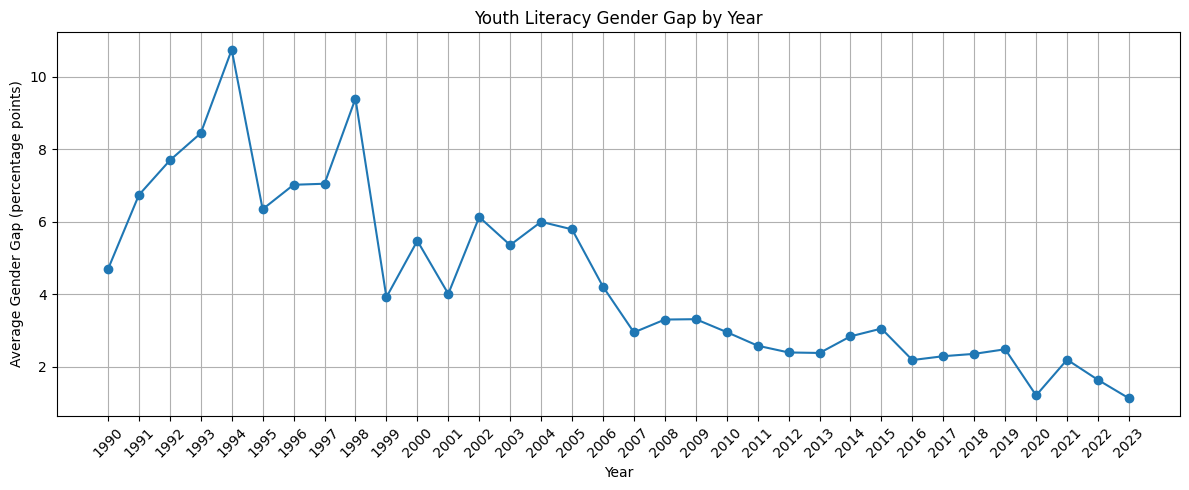

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    yearly_gender_gap["Year"],
    yearly_gender_gap["Literacy_Gender_Gap"],
    marker="o"
)

plt.title("Youth Literacy Gender Gap by Year")
plt.xlabel("Year")
plt.ylabel("Average Gender Gap (percentage points)")
plt.xticks(yearly_gender_gap["Year"], rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

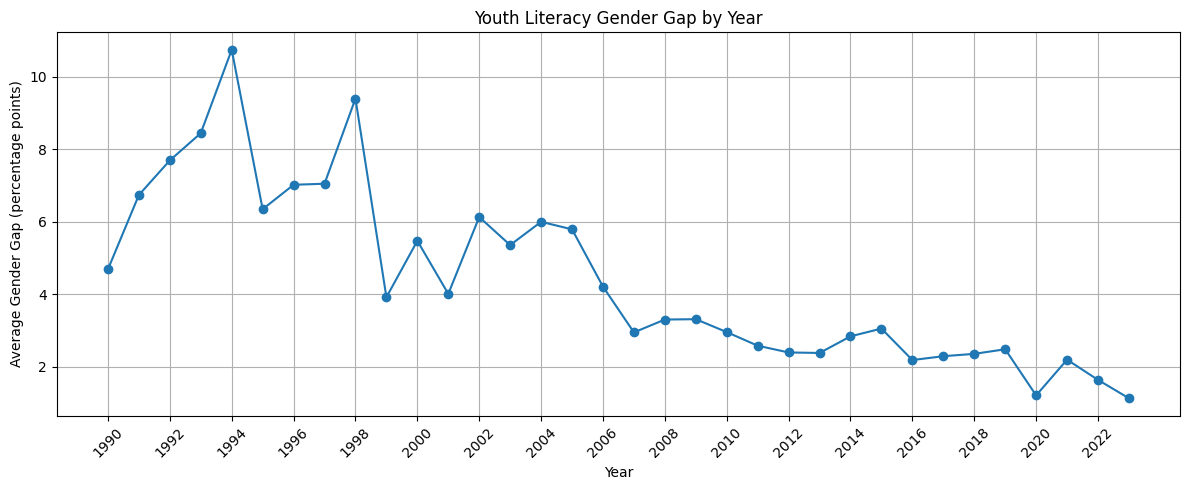

In [ ]:
plt.figure(figsize=(12, 5))

plt.plot(
    yearly_gender_gap["Year"],
    yearly_gender_gap["Literacy_Gender_Gap"],
    marker="o"
)

plt.title("Youth Literacy Gender Gap by Year")
plt.xlabel("Year")
plt.ylabel("Average Gender Gap (percentage points)")
plt.xticks(range(1990, 2024, 2), rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
url_gdp = "https://ourworldindata.org/grapher/gdp-per-capita-worldbank.csv"

response = requests.get(
    url_gdp,
    headers={"User-Agent": "Mozilla/5.0"}
)

df_gdp = pd.read_csv(StringIO(response.text))

print("Shape:", df_gdp.shape)
print("Columns:", df_gdp.columns.tolist())
print(df_gdp.head())

Shape: (7445, 5)
Columns: ['Entity', 'Code', 'Year', 'GDP per capita', 'World region according to OWID']
        Entity Code  Year  GDP per capita World region according to OWID
0  Afghanistan  AFG  2000       1617.8264                           Asia
1  Afghanistan  AFG  2001       1454.1108                           Asia
2  Afghanistan  AFG  2002       1774.3087                           Asia
3  Afghanistan  AFG  2003       1815.9282                           Asia
4  Afghanistan  AFG  2004       1776.9182                           Asia


In [ ]:
df_gdp = df_gdp[
    (df_gdp["Year"] >= 1990) &
    (df_gdp["Year"] <= 2023)
]

df_gdp = df_gdp.drop(
    columns=["World region according to OWID"]
)

df_gdp = df_gdp.rename(columns={
    "GDP per capita": "GDP_Per_Capita"
})

print("Shape:", df_gdp.shape)
print("\nMissing values:")
print(df_gdp.isnull().sum())
print("\nDuplicates:", df_gdp.duplicated().sum())
print("\nYear range:", df_gdp["Year"].min(), "-", df_gdp["Year"].max())
print("\nColumns:", df_gdp.columns.tolist())

Shape: (7039, 4)

Missing values:
Entity            0
Code              0
Year              0
GDP_Per_Capita    0
dtype: int64

Duplicates: 0

Year range: 1990 - 2023

Columns: ['Entity', 'Code', 'Year', 'GDP_Per_Capita']


In [ ]:
df_gdp = df_gdp[
    (df_gdp["Year"] >= 1990) &
    (df_gdp["Year"] <= 2023)
]

df_gdp = df_gdp.drop(
    columns=["World region according to OWID"]
)

df_gdp = df_gdp.rename(columns={
    "GDP per capita": "GDP_Per_Capita"
})

print("Shape:", df_gdp.shape)
print("\nMissing values:")
print(df_gdp.isnull().sum())
print("\nDuplicates:", df_gdp.duplicated().sum())
print("\nYear range:", df_gdp["Year"].min(), "-", df_gdp["Year"].max())
print("\nColumns:", df_gdp.columns.tolist())

KeyError: "['World region according to OWID'] not found in axis"

In [ ]:
df_gdp = df_gdp.drop(
    columns=["World region according to OWID"],
    errors="ignore"
)

df_gdp = df_gdp.rename(columns={
    "GDP per capita": "GDP_Per_Capita"
})

print("Shape:", df_gdp.shape)
print("\nMissing values:")
print(df_gdp.isnull().sum())
print("\nDuplicates:", df_gdp.duplicated().sum())
print("\nYear range:", df_gdp["Year"].min(), "-", df_gdp["Year"].max())
print("\nColumns:", df_gdp.columns.tolist())

In [ ]:
url_schooling = "https://ourworldindata.org/grapher/literacy-rates-vs-average-years-of-schooling.csv"

response = requests.get(
    url_schooling,
    headers={"User-Agent": "Mozilla/5.0"}
)

df_schooling = pd.read_csv(
    StringIO(response.text)
)

print("Shape:", df_schooling.shape)
print("Columns:", df_schooling.columns.tolist())
print(df_schooling.head())

In [ ]:
df_schooling = df_schooling[
    (df_schooling["Year"] >= 1990) &
    (df_schooling["Year"] <= 2023)
]

df_schooling = df_schooling.drop(
    columns=["World region according to OWID"],
    errors="ignore"
)

df_schooling = df_schooling.rename(columns={
    "Literacy rate": "Literacy_Rate",
    "Average years of education for 15-64 years olds":
        "Average_Years_Schooling"
})

print("Shape:", df_schooling.shape)
print("\nMissing values:")
print(df_schooling.isnull().sum())
print("\nDuplicates:", df_schooling.duplicated().sum())
print("\nYear range:",
      df_schooling["Year"].min(), "-",
      df_schooling["Year"].max())
print("\nColumns:", df_schooling.columns.tolist())

In [ ]:
url_schooling = "https://ourworldindata.org/grapher/literacy-rates-vs-average-years-of-schooling.csv"

response = requests.get(
    url_schooling,
    headers={"User-Agent": "Mozilla/5.0"}
)

df_schooling = pd.read_csv(StringIO(response.text))

print("Shape:", df_schooling.shape)
print(df_schooling.head())

In [ ]:
import pandas as pd
import numpy as np
import requests
from io import StringIO

url_schooling = "https://ourworldindata.org/grapher/literacy-rates-vs-average-years-of-schooling.csv"

response = requests.get(
    url_schooling,
    headers={"User-Agent": "Mozilla/5.0"}
)
response.raise_for_status()

df_schooling = pd.read_csv(StringIO(response.text))

print("Shape:", df_schooling.shape)
print(df_schooling.head())

In [ ]:
df_schooling = df_schooling[
    (df_schooling["Year"] >= 1990) &
    (df_schooling["Year"] <= 2023)
].copy()

df_schooling = df_schooling.drop(
    columns=["World region according to OWID"],
    errors="ignore"
)

df_schooling = df_schooling.rename(columns={
    "Literacy rate": "Literacy_Rate",
    "Average years of education for 15-64 years olds":
        "Average_Years_Schooling"
})

print("Shape:", df_schooling.shape)
print("\nMissing values:")
print(df_schooling.isnull().sum())
print("\nDuplicates:", df_schooling.duplicated().sum())
print("\nYear range:",
      df_schooling["Year"].min(), "-",
      df_schooling["Year"].max())
print("\nColumns:", df_schooling.columns.tolist())

In [ ]:
df_gdp_schooling = pd.merge(
    df_gdp,
    df_schooling,
    on=["Entity", "Code", "Year"],
    how="inner"
)

print("Shape:", df_gdp_schooling.shape)
print("\nMissing values:")
print(df_gdp_schooling.isnull().sum())
print("\nFirst 5 rows:")
print(df_gdp_schooling.head())

In [ ]:
url_gdp = "https://ourworldindata.org/grapher/gdp-per-capita-worldbank.csv"

response = requests.get(
    url_gdp,
    headers={"User-Agent": "Mozilla/5.0"}
)
response.raise_for_status()

df_gdp = pd.read_csv(StringIO(response.text))

print("Shape:", df_gdp.shape)
print(df_gdp.head())

In [ ]:
df_gdp = df_gdp[
    (df_gdp["Year"] >= 1990) &
    (df_gdp["Year"] <= 2023)
].copy()

df_gdp = df_gdp.drop(
    columns=["World region according to OWID"],
    errors="ignore"
)

df_gdp = df_gdp.rename(
    columns={"GDP per capita": "GDP_Per_Capita"}
)

print("Shape:", df_gdp.shape)
print("\nMissing values:")
print(df_gdp.isnull().sum())
print("\nDuplicate rows:", df_gdp.duplicated().sum())
print("\nYear range:", df_gdp["Year"].min(), "-", df_gdp["Year"].max())
print("\nColumns:", df_gdp.columns.tolist())

In [ ]:
df_gdp = df_gdp[
    (df_gdp["Year"] >= 1990) &
    (df_gdp["Year"] <= 2023)
].copy()

df_gdp = df_gdp.drop(
    columns=["World region according to OWID"],
    errors="ignore"
)

df_gdp = df_gdp.rename(
    columns={"GDP per capita": "GDP_Per_Capita"}
)

print("Shape:", df_gdp.shape)
print("\nMissing values:")
print(df_gdp.isnull().sum())
print("\nDuplicate rows:", df_gdp.duplicated().sum())
print("\nYear range:", df_gdp["Year"].min(), "-", df_gdp["Year"].max())
print("\nColumns:", df_gdp.columns.tolist())

In [ ]:
df_gdp_schooling = pd.merge(
    df_gdp,
    df_schooling,
    on=["Entity", "Code", "Year"],
    how="inner"
)

print("Shape:", df_gdp_schooling.shape)
print("\nMissing values:")
print(df_gdp_schooling.isnull().sum())
print("\nFirst 5 rows:")
print(df_gdp_schooling.head())

In [ ]:
df_gdp_schooling_valid = df_gdp_schooling.dropna(
    subset=["Literacy_Rate", "Average_Years_Schooling"]
).copy()

print("Original rows:", len(df_gdp_schooling))
print("Rows with both values:", len(df_gdp_schooling_valid))
print("Rows removed:", len(df_gdp_schooling) - len(df_gdp_schooling_valid))

print("\nMissing values after filtering:")
print(df_gdp_schooling_valid.isnull().sum())

In [ ]:
missing_percentage = (
    df_gdp_schooling.isnull().mean() * 100
).round(2)

print("Missing values percentage:")
print(missing_percentage)

In [ ]:
df_gdp_literacy = df_gdp_schooling.dropna(
    subset=["GDP_Per_Capita", "Literacy_Rate"]
).copy()

print("GDP + Literacy rows:", len(df_gdp_literacy))
print(df_gdp_literacy.head())

In [ ]:
correlation = df_gdp_literacy[
    ["GDP_Per_Capita", "Literacy_Rate"]
].corr()

print("Correlation:")
print(correlation)

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(
    df_gdp_literacy["GDP_Per_Capita"],
    df_gdp_literacy["Literacy_Rate"],
    alpha=0.5
)

plt.xlabel("GDP per Capita")
plt.ylabel("Literacy Rate (%)")
plt.title("GDP per Capita vs Literacy Rate")
plt.grid(True)
plt.show()

In [ ]:
df_schooling_corr = df_gdp_schooling.dropna(
    subset=["Literacy_Rate", "Average_Years_Schooling"]
).copy()

correlation = df_schooling_corr[
    ["Literacy_Rate", "Average_Years_Schooling"]
].corr()

print("Valid rows:", len(df_schooling_corr))
print("\nCorrelation:")
print(correlation)

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(
    df_schooling_corr["Average_Years_Schooling"],
    df_schooling_corr["Literacy_Rate"],
    alpha=0.6
)

plt.xlabel("Average Years of Schooling")
plt.ylabel("Literacy Rate (%)")
plt.title("Literacy Rate vs Average Years of Schooling")
plt.grid(True)
plt.show()

In [ ]:
df_featured = df_gdp_schooling.dropna(
    subset=["GDP_Per_Capita", "Average_Years_Schooling"]
).copy()

df_featured = df_featured[
    df_featured["Average_Years_Schooling"] > 0
].copy()

df_featured["GDP_Per_Schooling_Year"] = (
    df_featured["GDP_Per_Capita"] /
    df_featured["Average_Years_Schooling"]
)

print("Shape:", df_featured.shape)
print("\nNew feature:")
print(df_featured[
    ["Entity", "Year", "GDP_Per_Capita",
     "Average_Years_Schooling", "GDP_Per_Schooling_Year"]
].head())

In [ ]:
import pandas as pd
import requests
from io import StringIO

# Load GDP dataset
url_gdp = "https://ourworldindata.org/grapher/gdp-per-capita-worldbank.csv"
response = requests.get(url_gdp, headers={"User-Agent": "Mozilla/5.0"})
response.raise_for_status()
df_gdp = pd.read_csv(StringIO(response.text))

# Clean GDP dataset
df_gdp = df_gdp[
    (df_gdp["Year"] >= 1990) &
    (df_gdp["Year"] <= 2023)
].copy()

df_gdp = df_gdp.drop(
    columns=["World region according to OWID"],
    errors="ignore"
)

df_gdp = df_gdp.rename(
    columns={"GDP per capita": "GDP_Per_Capita"}
)

# Load Schooling dataset
url_schooling = "https://ourworldindata.org/grapher/literacy-rates-vs-average-years-of-schooling.csv"
response = requests.get(
    url_schooling,
    headers={"User-Agent": "Mozilla/5.0"}
)
response.raise_for_status()
df_schooling = pd.read_csv(StringIO(response.text))

# Clean Schooling dataset
df_schooling = df_schooling[
    (df_schooling["Year"] >= 1990) &
    (df_schooling["Year"] <= 2023)
].copy()

df_schooling = df_schooling.drop(
    columns=["World region according to OWID"],
    errors="ignore"
)

df_schooling = df_schooling.rename(columns={
    "Literacy rate": "Literacy_Rate",
    "Average years of education for 15-64 years olds":
        "Average_Years_Schooling"
})

# Merge datasets
df_gdp_schooling = pd.merge(
    df_gdp,
    df_schooling,
    on=["Entity", "Code", "Year"],
    how="inner"
)

# Feature Engineering
df_featured = df_gdp_schooling.dropna(
    subset=["GDP_Per_Capita", "Average_Years_Schooling"]
).copy()

df_featured = df_featured[
    df_featured["Average_Years_Schooling"] > 0
].copy()

df_featured["GDP_Per_Schooling_Year"] = (
    df_featured["GDP_Per_Capita"] /
    df_featured["Average_Years_Schooling"]
)

print("Merged dataset shape:", df_gdp_schooling.shape)
print("Feature dataset shape:", df_featured.shape)
print("\nNew feature preview:")
print(df_featured[
    ["Entity", "Year", "GDP_Per_Capita",
     "Average_Years_Schooling", "GDP_Per_Schooling_Year"]
].head())

In [ ]:
print("GDP per Schooling Year Summary:")
print(
    df_featured["GDP_Per_Schooling_Year"].describe()
)

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.hist(
    df_featured["GDP_Per_Schooling_Year"],
    bins=30,
    edgecolor="black"
)

plt.xlabel("GDP per Schooling Year")
plt.ylabel("Frequency")
plt.title("Distribution of GDP per Schooling Year")
plt.grid(axis="y", alpha=0.3)
plt.show()

In [ ]:
skewness = df_featured[
    "GDP_Per_Schooling_Year"
].skew()

print("Skewness:", round(skewness, 2))

In [ ]:
Q1 = df_featured["GDP_Per_Schooling_Year"].quantile(0.25)
Q3 = df_featured["GDP_Per_Schooling_Year"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df_featured[
    (df_featured["GDP_Per_Schooling_Year"] < lower_bound) |
    (df_featured["GDP_Per_Schooling_Year"] > upper_bound)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)
print("Number of outliers:", len(outliers))

In [ ]:
outliers_sorted = outliers.sort_values(
    by="GDP_Per_Schooling_Year",
    ascending=False
)

print(
    outliers_sorted[
        ["Entity", "Year", "GDP_Per_Capita",
         "Average_Years_Schooling",
         "GDP_Per_Schooling_Year"]
    ].head(10)
)

In [ ]:
df_featured["Outlier_Flag"] = (
    df_featured["GDP_Per_Schooling_Year"] > upper_bound
)

print(df_featured["Outlier_Flag"].value_counts())

print("\nOutlier percentage:")
print(
    round(
        df_featured["Outlier_Flag"].mean() * 100, 2
    ), "%"
)

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.boxplot(
    df_featured["GDP_Per_Schooling_Year"],
    vert=False
)

plt.xlabel("GDP per Schooling Year")
plt.title("Box Plot of GDP per Schooling Year")
plt.grid(axis="x", alpha=0.3)
plt.show()

In [ ]:
df_featured.to_csv(
    "global_education_featured.csv",
    index=False
)

print("CSV file saved successfully!")

In [ ]:
import sqlite3

conn = sqlite3.connect("education.db")

print("SQL database created successfully!")

In [ ]:
df_featured.to_sql(
    "education_data",
    conn,
    if_exists="replace",
    index=False
)

print("Dataset successfully added to SQL table!")

In [ ]:
query = """
SELECT *
FROM education_data
LIMIT 10;
"""

df_sql = pd.read_sql_query(query, conn)
df_sql

In [ ]:
query = """
SELECT
    Entity,
    ROUND(AVG(GDP_Per_Capita), 2) AS Average_GDP
FROM education_data
GROUP BY Entity
ORDER BY Average_GDP DESC
LIMIT 10;
"""

df_country_gdp = pd.read_sql_query(query, conn)
df_country_gdp

In [ ]:




    .dataframe tbody tr th:only-of-type {
        vertical-align: middle;
    }

    .dataframe tbody tr th {
        vertical-align: top;
    }

    .dataframe thead th {
        text-align: right;
    }





      Entity
      Average_GDP




      0
      Luxembourg
      114895.58


      1
      Singapore
      113289.13


      2
      Qatar
      113066.40


      3
      Macao
      91428.28


      4
      Brunei
      81095.54


      5
      Norway
      77811.19


      6
      Switzerland
      71606.47


      7
      United Arab Emirates
      71023.59


      8
      Ireland
      60630.96


      9
      Kuwait
      58842.60















    .colab-df-container {
      display:flex;
      gap: 12px;
    }

    .colab-df-convert {
      background-color: #E8F0FE;
      border: none;
      border-radius: 50%;
      cursor: pointer;
      display: none;
      fill: #1967D2;
      height: 32px;
      padding: 0 0 0 0;
      width: 32px;
    }

    .colab-df-convert:hover {
      background-color: #E2EBFA;
      box-shadow: 0px 1px 2px rgba(60, 64, 67, 0.3), 0px 1px 3px 1px rgba(60, 64, 67, 0.15);
      fill: #174EA6;
    }

    .colab-df-buttons div {
      margin-bottom: 4px;
    }

    [theme=dark] .colab-df-convert {
      background-color: #3B4455;
      fill: #D2E3FC;
    }

    [theme=dark] .colab-df-convert:hover {
      background-color: #434B5C;
      box-shadow: 0px 1px 3px 1px rgba(0, 0, 0, 0.15);
      filter: drop-shadow(0px 1px 2px rgba(0, 0, 0, 0.3));
      fill: #FFFFFF;
    }



      const buttonEl =
        document.querySelector('#df-032424a3-fcdf-4430-84ae-9b9d140201d6 button.colab-df-convert');
      buttonEl.style.display =
        google.colab.kernel.accessAllowed ? 'block' : 'none';

      async function convertToInteractive(key) {
        const element = document.querySelector('#df-032424a3-fcdf-4430-84ae-9b9d140201d6');
        const dataTable =
          await google.colab.kernel.invokeFunction('convertToInteractive',
                                                    [key], {});
        if (!dataTable) return;

        const docLinkHtml = 'Like what you see? Visit the ' +
          '<a target="_blank" href=https://colab.research.google.com/notebooks/data_table.ipynb>data table notebook</a>'
          + ' to learn more about interactive tables.';
        element.innerHTML = '';
        dataTable['output_type'] = 'display_data';
        await google.colab.output.renderOutput(dataTable, element);
        const docLink = document.createElement('div');
        docLink.innerHTML = docLinkHtml;
        element.appendChild(docLink);
      }






      .colab-df-generate {
        background-color: #E8F0FE;
        border: none;
        border-radius: 50%;
        cursor: pointer;
        display: none;
        fill: #1967D2;
        height: 32px;
        padding: 0 0 0 0;
        width: 32px;
      }

      .colab-df-generate:hover {
        background-color: #E2EBFA;
        box-shadow: 0px 1px 2px rgba(60, 64, 67, 0.3), 0px 1px 3px 1px rgba(60, 64, 67, 0.15);
        fill: #174EA6;
      }

      [theme=dark] .colab-df-generate {
        background-color: #3B4455;
        fill: #D2E3FC;
      }

      [theme=dark] .colab-df-generate:hover {
        background-color: #434B5C;
        box-shadow: 0px 1px 3px 1px rgba(0, 0, 0, 0.15);
        filter: drop-shadow(0px 1px 2px rgba(0, 0, 0, 0.3));
        fill: #FFFFFF;
      }








      (() => {
      const buttonEl =
        document.querySelector('#id_f7453b3e-c954-470d-ae49-3bb371ce389d button.colab-df-generate');
      buttonEl.style.display =
        google.colab.kernel.accessAllowed ? 'block' : 'none';

      buttonEl.onclick = () => {
        google.colab.notebook.generateWithVariable('df_country_gdp');
      }
      })();







In [ ]:
query = """
SELECT
    Entity,
    ROUND(AVG(GDP_Per_Capita), 2) AS Average_GDP
FROM education_data
GROUP BY Entity
ORDER BY Average_GDP DESC
LIMIT 10;
"""

df_country_gdp = pd.read_sql_query(query, conn)
df_country_gdp

In [ ]:
query = """
SELECT
    Entity,
    ROUND(AVG(Average_Years_Schooling), 2)
        AS Average_Schooling
FROM education_data
WHERE Average_Years_Schooling IS NOT NULL
GROUP BY Entity
ORDER BY Average_Schooling DESC
LIMIT 10;
"""

df_schooling_sql = pd.read_sql_query(query, conn)
df_schooling_sql

In [ ]:
import pandas as pd

In [ ]:
df_schooling_sql = pd.read_sql_query(query, conn)
df_schooling_sql

In [ ]:
import sqlite3
import pandas as pd

conn = sqlite3.connect("education.db")

print("SQL connection created successfully!")

In [ ]:
print("df_featured" in globals())

In [ ]:
from google.colab import files
uploaded = files.upload()

In [ ]:
import pandas as pd

df_featured = pd.read_csv("global_education_featured.csv")

print("Dataset loaded successfully!")
print(df_featured.shape)

In [ ]:
import sqlite3

conn = sqlite3.connect("education.db")

df_featured.to_sql(
    "education_data",
    conn,
    if_exists="replace",
    index=False
)

print("SQL table created successfully!")

In [ ]:
query = """
SELECT
    Entity,
    ROUND(AVG(Average_Years_Schooling), 2)
        AS Average_Schooling
FROM education_data
WHERE Average_Years_Schooling IS NOT NULL
GROUP BY Entity
ORDER BY Average_Schooling DESC
LIMIT 10;
"""

df_schooling_sql = pd.read_sql_query(query, conn)
df_schooling_sql

In [ ]:
query = """
SELECT
    Entity,
    ROUND(AVG(GDP_Per_Capita), 2) AS Average_GDP,
    ROUND(AVG(Average_Years_Schooling), 2)
        AS Average_Schooling
FROM education_data
WHERE GDP_Per_Capita IS NOT NULL
  AND Average_Years_Schooling IS NOT NULL
GROUP BY Entity
ORDER BY Average_Schooling DESC
LIMIT 10;
"""

df_gdp_schooling_sql = pd.read_sql_query(query, conn)
df_gdp_schooling_sql

In [ ]:
correlation = df_gdp_schooling_sql[
    ["Average_GDP", "Average_Schooling"]
].corr()

print(correlation)

In [ ]:
query = """
SELECT
    Year,
    ROUND(AVG(GDP_Per_Capita), 2) AS Average_GDP
FROM education_data
GROUP BY Year
ORDER BY Year;
"""

df_yearly_gdp = pd.read_sql_query(query, conn)
df_yearly_gdp

In [ ]:
query = """
SELECT
    Year,
    ROUND(AVG(Average_Years_Schooling), 2)
        AS Average_Schooling
FROM education_data
WHERE Average_Years_Schooling IS NOT NULL
GROUP BY Year
ORDER BY Year;
"""

df_yearly_schooling = pd.read_sql_query(query, conn)
df_yearly_schooling

In [ ]:
query = """
SELECT
    Entity,
    Year,
    GDP_Per_Schooling_Year
FROM education_data
WHERE Outlier_Flag = 1
ORDER BY GDP_Per_Schooling_Year DESC
LIMIT 10;
"""

df_outliers_sql = pd.read_sql_query(query, conn)
df_outliers_sql

In [ ]:
query = """
SELECT
    Entity,
    COUNT(*) AS Outlier_Count
FROM education_data
WHERE Outlier_Flag = 1
GROUP BY Entity
ORDER BY Outlier_Count DESC
LIMIT 10;
"""

df_outlier_count = pd.read_sql_query(query, conn)
df_outlier_count

In [ ]:
query = """
SELECT
    Outlier_Flag,
    COUNT(*) AS Record_Count,
    ROUND(
        COUNT(*) * 100.0 /
        (SELECT COUNT(*) FROM education_data),
        2
    ) AS Percentage
FROM education_data
GROUP BY Outlier_Flag
ORDER BY Outlier_Flag;
"""

df_outlier_summary = pd.read_sql_query(query, conn)
df_outlier_summary

In [ ]:
import pandas as pd
import sqlite3

conn = sqlite3.connect("education.db")

query = """
SELECT
    Outlier_Flag,
    COUNT(*) AS Record_Count,
    ROUND(
        COUNT(*) * 100.0 /
        (SELECT COUNT(*) FROM education_data),
        2
    ) AS Percentage
FROM education_data
GROUP BY Outlier_Flag
ORDER BY Outlier_Flag;
"""

df_outlier_summary = pd.read_sql_query(query, conn)
df_outlier_summary

In [ ]:
import pandas as pd
import sqlite3

# CSV load
df_featured = pd.read_csv("global_education_featured.csv")

# SQL database connection
conn = sqlite3.connect("education.db")

# Recreate SQL table
df_featured.to_sql(
    "education_data",
    conn,
    if_exists="replace",
    index=False
)

print("SQL table recreated successfully!")

# Check table
check = pd.read_sql_query(
    "SELECT COUNT(*) AS total_records FROM education_data;",
    conn
)

check

In [ ]:
from google.colab import files

uploaded = files.upload()

In [ ]:
import pandas as pd
import sqlite3

# Load uploaded CSV
df_featured = pd.read_csv("global_education_featured.csv")

# Create SQL database
conn = sqlite3.connect("education.db")

# Create SQL table
df_featured.to_sql(
    "education_data",
    conn,
    if_exists="replace",
    index=False
)

print("SQL table recreated successfully!")
print("Total records:", len(df_featured))

In [ ]:
query = """
SELECT
    Outlier_Flag,
    COUNT(*) AS Record_Count,
    ROUND(
        COUNT(*) * 100.0 /
        (SELECT COUNT(*) FROM education_data),
        2
    ) AS Percentage
FROM education_data
GROUP BY Outlier_Flag
ORDER BY Outlier_Flag;
"""

df_outlier_summary = pd.read_sql_query(query, conn)
df_outlier_summary

In [ ]:
query = """
SELECT
    Entity,
    COUNT(*) AS Outlier_Count
FROM education_data
WHERE Outlier_Flag = 1
GROUP BY Entity
ORDER BY Outlier_Count DESC
LIMIT 10;
"""

df_outlier_country = pd.read_sql_query(query, conn)
df_outlier_country

In [ ]:
query = """
SELECT
    Year,
    ROUND(AVG(GDP_Per_Capita), 2) AS Average_GDP,
    ROUND(AVG(Average_Years_Schooling), 2) AS Average_Schooling
FROM education_data
GROUP BY Year
ORDER BY Year;
"""

df_yearly_summary = pd.read_sql_query(query, conn)
df_yearly_summary

NameError: name 'conn' is not defined

In [ ]:
df_featured.to_csv("global_education_featured.csv", index=False)

from google.colab import files
files.download("global_education_featured.csv")

In [ ]:
%whos

Variable                  Type         Data/Info
------------------------------------------------
StringIO                  type         <class '_io.StringIO'>
data                      str          Entity,Code,Year,Literacy<...>\nZimbabwe,ZWE,2019,93.23
data_gdp                  str          Entity,Code,Year,GDP per <...>,ZWE,2025,5529.233,Africa
data_illiteracy           str          Entity,Code,Year,Illitera<...>,ZWE,2019,6.7699966,93.23
data_schooling            str          Entity,Code,Year,Literacy<...>020,,8.32,15526887,Africa
data_youth                str          Entity,Code,Year,Literacy<...>E,2019,90.77,94.22,Africa
df_adult                  DataFrame               Entity Code  Y<...>\n[1310 rows x 4 columns]
df_both_available         DataFrame               Entity Code  Y<...>n\n[159 rows x 6 columns]
df_gdp                    DataFrame               Entity Code  Y<...>\n[7039 rows x 4 columns]
df_gdp_schooling          DataFrame               Entity Code  Y<...>\n[1897 row

In [ ]:
print("Notebook working")

Notebook working


In [ ]:
import pandas as pd

url = "https://ourworldindata.org/grapher/literacy-rate-adults.csv"
df_adult = pd.read_csv(url)

print(df_adult.shape)
df_adult.head()

(1833, 4)


,Entity,Code,Year,Literacy rate among adults
0,Afghanistan,AFG,1979,18.160000
1,Afghanistan,AFG,2011,31.450000
2,Afghanistan,AFG,2015,33.750000
3,Afghanistan,AFG,2020,36.014965
4,Afghanistan,AFG,2021,37.270000


In [ ]:
url = "https://ourworldindata.org/grapher/literacy-rate-of-young-men-and-women.csv"

df_youth = pd.read_csv(url)

print(df_youth.shape)
df_youth.head()

(2077, 6)


,Entity,Code,Year,Literacy rate among young men,Literacy rate among young women,World region according to OWID
0,Afghanistan,AFG,1979,45.800000,11.140000,Asia
1,Afghanistan,AFG,2011,61.880000,32.110000,Asia
2,Afghanistan,AFG,2015,57.740000,25.480000,Asia
3,Afghanistan,AFG,2020,68.800964,40.055595,Asia
4,Afghanistan,AFG,2021,71.240000,41.590000,Asia


In [ ]:
df_youth = df_youth.rename(columns={
    "Literacy rate among young men": "Youth_Male_Literacy_Rate",
    "Literacy rate among young women": "Youth_Female_Literacy_Rate"
})

df_youth["Literacy_Gender_Gap"] = (
    df_youth["Youth_Male_Literacy_Rate"]
    - df_youth["Youth_Female_Literacy_Rate"]
)

print(df_youth.shape)
df_youth.head()

(2077, 7)


,Entity,Code,Year,Youth_Male_Literacy_Rate,Youth_Female_Literacy_Rate,World region according to OWID,Literacy_Gender_Gap
0,Afghanistan,AFG,1979,45.800000,11.140000,Asia,34.660000
1,Afghanistan,AFG,2011,61.880000,32.110000,Asia,29.770000
2,Afghanistan,AFG,2015,57.740000,25.480000,Asia,32.260000
3,Afghanistan,AFG,2020,68.800964,40.055595,Asia,28.745369
4,Afghanistan,AFG,2021,71.240000,41.590000,Asia,29.650000


In [ ]:
url_gdp = "https://ourworldindata.org/grapher/gdp-per-capita-worldbank.csv"

df_gdp = pd.read_csv(url_gdp)

print(df_gdp.shape)
df_gdp.head()

(7445, 5)


,Entity,Code,Year,GDP per capita,World region according to OWID
0,Afghanistan,AFG,2000,1617.8264,Asia
1,Afghanistan,AFG,2001,1454.1108,Asia
2,Afghanistan,AFG,2002,1774.3087,Asia
3,Afghanistan,AFG,2003,1815.9282,Asia
4,Afghanistan,AFG,2004,1776.9182,Asia


In [ ]:
df_gdp = df_gdp.rename(columns={
    "GDP per capita": "GDP_Per_Capita"
})

df_gdp = df_gdp[["Entity", "Code", "Year", "GDP_Per_Capita"]]

print(df_gdp.shape)
df_gdp.head()

(7445, 4)


,Entity,Code,Year,GDP_Per_Capita
0,Afghanistan,AFG,2000,1617.8264
1,Afghanistan,AFG,2001,1454.1108
2,Afghanistan,AFG,2002,1774.3087
3,Afghanistan,AFG,2003,1815.9282
4,Afghanistan,AFG,2004,1776.9182


In [ ]:
url_schooling = "https://ourworldindata.org/grapher/literacy-rates-vs-average-years-of-schooling.csv"

df_schooling = pd.read_csv(url_schooling)

print(df_schooling.shape)
df_schooling.head()

(5403, 7)


,Entity,Code,Year,Literacy rate,Average years of education for 15-64 years olds,Population,World region according to OWID
0,Afghanistan,AFG,1870,NaN,0.01,4101170.0,Asia
1,Afghanistan,AFG,1875,NaN,0.01,4193635.0,Asia
2,Afghanistan,AFG,1880,NaN,0.01,4288021.0,Asia
3,Afghanistan,AFG,1885,NaN,0.01,4384343.0,Asia
4,Afghanistan,AFG,1890,NaN,0.01,4482635.0,Asia


In [ ]:
df_schooling = df_schooling.rename(columns={
    "Literacy rate": "Literacy_Rate",
    "Average years of education for 15-64 years olds": "Average_Years_Schooling"
})

df_schooling = df_schooling[
    ["Entity", "Code", "Year", "Literacy_Rate",
     "Average_Years_Schooling", "Population"]
]

df_schooling = df_schooling[df_schooling["Year"].between(1990, 2023)]

print(df_schooling.shape)
df_schooling.head()

(2204, 6)


,Entity,Code,Year,Literacy_Rate,Average_Years_Schooling,Population
25,Afghanistan,AFG,1990,NaN,2.06,12045664.0
26,Afghanistan,AFG,1995,NaN,2.40,17065837.0
27,Afghanistan,AFG,2000,NaN,3.03,20130334.0
28,Afghanistan,AFG,2005,NaN,3.32,24404575.0
29,Afghanistan,AFG,2010,NaN,3.93,28284088.0


In [ ]:
df_youth_clean = df_youth[
    ["Entity", "Code", "Year",
     "Youth_Male_Literacy_Rate",
     "Youth_Female_Literacy_Rate",
     "Literacy_Gender_Gap"]
].copy()

print(df_youth_clean.shape)

(2077, 6)


In [ ]:
# Merge GDP and schooling data
df_final = pd.merge(
    df_schooling,
    df_gdp,
    on=["Entity", "Code", "Year"],
    how="inner"
)

# Merge youth literacy data
df_final = pd.merge(
    df_final,
    df_youth_clean,
    on=["Entity", "Code", "Year"],
    how="left"
)

# Keep rows with GDP and schooling information
df_final = df_final.dropna(
    subset=["GDP_Per_Capita", "Average_Years_Schooling"]
)

# Remove invalid schooling values
df_final = df_final[df_final["Average_Years_Schooling"] > 0].copy()

# Create derived feature
df_final["GDP_Per_Schooling_Year"] = (
    df_final["GDP_Per_Capita"] /
    df_final["Average_Years_Schooling"]
)

print(df_final.shape)
df_final.head()

(809, 11)


,Entity,Code,Year,Literacy_Rate,Average_Years_Schooling,Population,GDP_Per_Capita,Youth_Male_Literacy_Rate,Youth_Female_Literacy_Rate,Literacy_Gender_Gap,GDP_Per_Schooling_Year
0,Afghanistan,AFG,2000,NaN,3.03,20130334.0,1617.8264,NaN,NaN,NaN,533.936106
1,Afghanistan,AFG,2005,NaN,3.32,24404575.0,1908.1147,NaN,NaN,NaN,574.733343
2,Afghanistan,AFG,2010,NaN,3.93,28284088.0,2848.5862,NaN,NaN,NaN,724.831094
4,Afghanistan,AFG,2015,33.750000,4.81,33831767.0,2967.6921,57.740000,25.480000,32.260000,616.983805
5,Afghanistan,AFG,2020,36.014965,5.69,39068977.0,2769.6858,68.800964,40.055595,28.745369,486.763761


In [ ]:
df_final.to_csv("global_education_featured.csv", index=False)

from google.colab import files
files.download("global_education_featured.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
print("Dataset Shape:", df_final.shape)

print("\nSummary Statistics:")
display(df_final[
    ["Literacy_Rate",
     "Average_Years_Schooling",
     "GDP_Per_Capita",
     "Literacy_Gender_Gap"]
].describe().round(2))

Dataset Shape: (809, 11)

Summary Statistics:


,Literacy_Rate,Average_Years_Schooling,GDP_Per_Capita,Literacy_Gender_Gap
count,155.00,809.00,809.00,175.00
mean,82.84,8.19,21923.06,2.79
std,16.50,2.97,22874.12,7.34
min,28.67,0.95,525.42,-16.76
25%,77.34,5.94,4878.25,-0.55
50%,89.94,8.51,12702.16,0.00
75%,94.20,10.67,35264.71,2.48
max,99.79,13.74,131434.36,32.67


In [ ]:
print(df_final.shape)

(809, 11)


In [ ]:

import pandas as pd
import numpy as np
from google.colab import files
from io import BytesIO

# Upload the final dataset CSV
uploaded = files.upload()

file_name = next(iter(uploaded))
df_final = pd.read_csv(BytesIO(uploaded[file_name]))

print("Dataset loaded successfully!")
print("Dataset Shape:", df_final.shape)

# Convert numeric columns
numeric_cols = [
    "Year",
    "Literacy_Rate",
    "Average_Years_Schooling",
    "GDP_Per_Capita",
    "Literacy_Gender_Gap",
    "Youth_Male_Literacy_Rate",
    "Youth_Female_Literacy_Rate"
]

for col in numeric_cols:
    if col in df_final.columns:
        df_final[col] = pd.to_numeric(df_final[col], errors="coerce")

# 1. Summary statistics
print("\n--- SUMMARY STATISTICS ---")
display(
    df_final[
        ["Literacy_Rate", "Average_Years_Schooling",
         "GDP_Per_Capita", "Literacy_Gender_Gap"]
    ].describe().round(2)
)

# 2. Year-wise trends
print("\n--- YEAR-WISE TRENDS ---")

yearly_analysis = df_final.groupby("Year").agg({
    "Literacy_Rate": "mean",
    "Average_Years_Schooling": "mean",
    "GDP_Per_Capita": "mean",
    "Literacy_Gender_Gap": "mean"
}).round(2)

display(yearly_analysis)

# 3. Country-wise comparison
print("\n--- COUNTRY-WISE ANALYSIS ---")

country_analysis = df_final.groupby("Entity").agg({
    "Literacy_Rate": "mean",
    "Average_Years_Schooling": "mean",
    "GDP_Per_Capita": "mean",
    "Literacy_Gender_Gap": "mean"
}).round(2)

display(country_analysis.head(10))

# 4. Correlation analysis
print("\n--- CORRELATION ANALYSIS ---")

correlation = df_final[
    ["Literacy_Rate", "Average_Years_Schooling",
     "GDP_Per_Capita", "Literacy_Gender_Gap"]
].corr().round(3)

display(correlation)

print("\nPython analysis completed!")


TypeError: 'NoneType' object is not subscriptable

In [ ]:
import pandas as pd
import numpy as np
from google.colab import files
from io import BytesIO

# Upload the final dataset CSV
uploaded = files.upload()

file_name = next(iter(uploaded))
df_final = pd.read_csv(BytesIO(uploaded[file_name]))

print("Dataset loaded successfully!")
print("Dataset Shape:", df_final.shape)

# Convert numeric columns
numeric_cols = [
    "Year",
    "Literacy_Rate",
    "Average_Years_Schooling",
    "GDP_Per_Capita",
    "Literacy_Gender_Gap",
    "Youth_Male_Literacy_Rate",
    "Youth_Female_Literacy_Rate"
]

for col in numeric_cols:
    if col in df_final.columns:
        df_final[col] = pd.to_numeric(df_final[col], errors="coerce")

# 1. Summary statistics
print("\n--- SUMMARY STATISTICS ---")
display(
    df_final[
        ["Literacy_Rate", "Average_Years_Schooling",
         "GDP_Per_Capita", "Literacy_Gender_Gap"]
    ].describe().round(2)
)

# 2. Year-wise trends
print("\n--- YEAR-WISE TRENDS ---")

yearly_analysis = df_final.groupby("Year").agg({
    "Literacy_Rate": "mean",
    "Average_Years_Schooling": "mean",
    "GDP_Per_Capita": "mean",
    "Literacy_Gender_Gap": "mean"
}).round(2)

display(yearly_analysis)

# 3. Country-wise comparison
print("\n--- COUNTRY-WISE ANALYSIS ---")

country_analysis = df_final.groupby("Entity").agg({
    "Literacy_Rate": "mean",
    "Average_Years_Schooling": "mean",
    "GDP_Per_Capita": "mean",
    "Literacy_Gender_Gap": "mean"
}).round(2)

display(country_analysis.head(10))

# 4. Correlation analysis
print("\n--- CORRELATION ANALYSIS ---")

correlation = df_final[
    ["Literacy_Rate", "Average_Years_Schooling",
     "GDP_Per_Capita", "Literacy_Gender_Gap"]
].corr().round(3)

display(correlation)

print("\nPython analysis completed!")


In [ ]:
print("Dataset Shape:", df_final.shape)
print("\nColumn Names:")
print(df_final.columns.tolist())

display(df_final.head())

In [ ]:
print("Dataset Shape:", df_final.shape)
display(df_final.head())